# 굿즈 상세페이지 생성: 단계별 일괄 처리와 서비스 시간 (10/30)

게임과 굿즈를 넣으면 굿즈 판매용 상세페이지를 만든다. 지금까지 따로 확인한 기능 A(문구)·B(문구 합성)·C(게임 그림체 이미지)·F(굿즈 목업)·D(굿즈 연출 배경)를 한 흐름으로 잇고, 서비스로 돌릴 때 페이지 1장에 걸리는 시간을 잰다. 모델마다 별도 프로세스에서 한 번만 불러 그 단계의 항목을 모두 처리하는 단계별 일괄 처리로 돌리고, 페이지마다 모델을 새로 불러오는 경우와 측정값으로 비교한다. 서비스 흐름을 재는 실험이라 이전 노트북에서 만든 이미지는 쓰지 않고 문구·이미지를 모두 이 실행에서 새로 만든다.

### 상세페이지 구성

가로 860px(근거: https://clobe.ai/blog/online-shopping-mall-product-image-size), 세로 길이 제한 없음, 위에서 아래로 섹션 5개다.

| 섹션 | 내용 |
|---|---|
| ① | C 게임 그림체 이미지 + 제목. 제목은 07 "문구 합성 함수"의 `compose`(B의 Pillow 합성)로 올리고, 부제는 게임 정보 문장(13 `GAMES` info)이다 |
| ② | 게임 소개 문구 (기능 A) |
| ③ | F 굿즈 목업 이미지 + 문구. 서비스에서는 22 합성 후보(머그 3장, 옷·에코백 2장)를 모두 보여 주고 소비자가 고른 것을 넣는다. 이 노트북에는 고르는 화면이 없으므로 "설정: 이미지"의 가상 예시 선택(`MOCKUP_CHOICE`)을 넣는다 |
| ④ | D 굿즈 연출 이미지 + 문구 |
| ⑤ | 구매 정보. "설정"의 가상 예시 입력(`PURCHASE`)을 쓰고 페이지에 "예시"로 표시한다 |

### 범위

게임 3개 × 굿즈 1개 × D 방식 2개 = 6페이지. 문구·C 이미지·목업 후보는 게임마다 한 번 만들어 D 방식 두 페이지가 같이 쓴다.

| 게임 | 굿즈 |
|---|---|
| 냥기사 (`nai`) | `tshirt_02` |
| KayKit (`kaykit`) | `mug_01` |
| 0x72 (`x72`) | `tote_01` |

D 장면은 `desk`다(16·17·20과 같은 장면 문구).

| D 방식 | 처리 | 근거 |
|---|---|---|
| (a) R1n | IC-Light 결과의 굿즈 밖 배경 + 조명만 옮긴 원본 굿즈, 흐림 32 | 16 `R1n_s32_ic` |
| (b) YR1n | Y 결과에 검은 띠가 있으면 seed 0 → 1 → 2로 다시 생성(최대 3번) → 굿즈 자리를 메운 Y 배경을 IC-Light 배경 조건으로 → Y 배경 위에 조명만 옮긴 원본 굿즈, 흐림 8 | 20 띠 판정 기준·다시 생성, 17 `YR1n_s8_fill_y` |

### 정한 설정과 근거

- 문구 (Qwen3-VL-8B): 13 ③(지시문 예시 + 구체적 재요청, 10/30 채택)과 19의 조사 수정을 그대로 쓴다. 지시문·검증 규칙·재요청 문구는 19 "설정"·"후보 지시문·재요청 문구" 셀에서 그대로 옮겼다.
  - 11/03 변경: 구체적 재요청의 고치는 방법을 25 후보 3 편집 지시(`FB_HINTS_EDIT`, 25 "후보 지시문·재요청 문구" 셀과 같음)로 바꿨다. 25에서 0x72가 0.800 → 1.000이 됐고 앱도 이 문구를 쓴다. 이전 재요청 문구로 만든 문구 기록은 `dp_copy_records_before_fb_edit.csv`에 남긴다.
  - 순서: 첫 생성(샘플링 없음) → 규칙 실패면 샘플링 후보 4개 중 실패 항목이 가장 적은 것 → 그래도 실패면 실패 이유와 고치는 방법을 붙여 1번 다시 요청
  - 규칙: 사용자 입력에 없는 판촉 표현(할인·특가·무료·이벤트·출시·사전예약·선물)과 숫자(%·월·일) 금지, 금지 표현, 꼭 넣을 문구, 문장 수
  - 섹션별 요청: ②는 기능 A 요청 그대로다(store 2문장 + sns 1문장, 꼭 넣을 문구는 sns 안에). ①③④는 A 지시문에서 요청 문장과 출력 형식 줄만 바꾼다.

    | 섹션 | 출력 | 형식 규칙 근거 |
    |---|---|---|
    | ① 제목 | `title` 한 줄, 20자 이내 | 08 기능 B 제목 규칙 "20자 이내". 11/03 "1문장" 대신 "한 줄"로 바꿈: "4인 협동! 픽셀 던전 모험"처럼 느낌표가 들어간 제목이 문장 2개로 세어져 실패했기 때문 |
    | ③ 목업 문구 | `copy` 2문장, 존댓말 | A store와 같은 문장 수. 존댓말은 11/04 추가 |
    | ④ 연출 문구 | `copy` 2문장, 존댓말 | A store와 같은 문장 수. 존댓말은 11/04 추가 |

  - 11/04 변경: ③④ 지시문에 "모든 문장은 존댓말(~요, ~니다)로 끝내줘." 줄을 넣고, `check_section`에서 문장마다 존댓말 어미(~요, ~니다, ~니까, ~죠, ~시오)로 끝나는지 검사한다. 실패하면 다른 규칙과 같은 순서(샘플링 후보 4개 → 재요청 1번)로 다시 만들고, 재요청에는 "위 문장을 존댓말로 끝나게 고쳐 써" 줄을 붙인다. 이유: 이전 실행에서 ②는 세 게임 모두 존댓말인데 냥기사·KayKit ④와 0x72 ③에 "…있어."로 끝나는 반말 문장이 있어 한 페이지에서 말투가 섞였다(앱 상세 페이지 작업에서도 ④가 반말). 이전 실행의 문구는 `dp_copy_records.csv` 이전 판(11/04 오전)이다. 명사로 끝나는 문장도 이 검사에 걸린다.
  - 11/04 변경: ② `check`에 sns·store 겹침 검사를 넣었다. 공백·문장부호를 뺀 sns와 가장 비슷한 store 문장의 유사도(`difflib.SequenceMatcher`)가 0.9 이상이면 실패로 보고, 재요청에는 "sns 문장을 store 문장과 다른 내용으로 다시 써" 줄을 붙인다. 이유: 앱 A 작업(리치의 모험)에서 sns가 store 첫 문장과 똑같은데 규칙 통과로 나왔다. 이전 A 후보 2,255개에서 0.9 근처 값이 드물고 0.9 이상은 한두 단어만 다른 문장이었다. 이전 21 ② 후보는 최대 0.452라 이 검사로 바뀌는 것은 없다.

  - ①③④의 사용자 입력 줄은 판매 포인트만 준다(13 `must_task`의 `pin` 줄). 꼭 넣을 문구는 A처럼 ② sns에만 넣고, ①③④ 지시문에서는 규칙 1의 꼭 넣을 문구 설명·예시 줄을 뺀다(주지 않은 문구를 넣으라는 지시가 되지 않게). 판촉 표현 허용 범위는 A와 같이 사용자 입력 전체(판매 포인트 + 꼭 넣을 문구)다.
  - ①③④ 검증은 A의 `check`와 같은 판촉·숫자·금지 표현 규칙에 섹션 형식(키, 문장 수, 글자 수)만 바꾼 `check_section`이다. 섹션 단위 문구는 처음 시험하므로 섹션마다 규칙 통과 여부와 생성·재요청 횟수를 기록한다.
  - 입력 이미지: 13과 같은 표본(게임마다 5장, seed 0) 중 게임별 첫 장. 문구 단계가 이미지 생성보다 먼저라 이 실행의 생성 이미지는 보지 않는다.
- C: 12 설정(`outputs/promo_c/c_config.json`)을 읽어 그대로 쓴다(프롬프트, 부정 프롬프트, IP-Adapter 설정, 참조 이미지, 1216×832, Euler Ancestral 28스텝, CFG 5, bf16). 장면은 14가 인쇄할 그림으로 고른 요청(냥기사 B0, KayKit B2, 0x72 B4), seed 0, IP-Adapter 켬이다.
  - 냥기사: 18 결정대로 animagine-xl-4.0-zero로 50장·1,600스텝 학습한 LoRA(`models/lora/sweep/zero_trigger_n50`)를 animagine-xl-4.0에 붙이고, 장면 뒤에 트리거 `nyang_knight_style`을 붙인다. IP-Adapter 0.5를 함께 쓴다.
  - KayKit·0x72: 12 설정 그대로(IP-Adapter만, KayKit은 그림체 블록, 0x72는 Compel 장면 가중치)
- F 목업 (11/02 변경): 22 합성 방식. 인쇄할 그림은 이 실행의 C 이미지다.
  - 변경 이유: 처음 실행(11/02)의 F0(SDXL img2img + IP-Adapter, strength 0.45)은 굿즈에 그림이 거의 찍히지 않았다(14 그림 유사도 0.530). 22에서 합성(F1)에 매핑을 더한 후보를 비교했고, 후보를 모두 만들어 소비자가 고르기로 했다(Notion F 페이지 "결정 (11/02, F 방식)").
  - 후보: 머그는 F1·F1curve(위아래 휨)·F1spec(반사광), 옷·에코백은 F1·F1cloth(천 질감). 설정값은 22와 같고, 22 `f1m_config.json`의 후보별 설정과 같은지 확인한다.
  - 인쇄 영역·머그 휨: 22 기록(`print_boxes_22.csv`, `mug_curve.csv`)을 그대로 쓴다. 굿즈 마스크는 14 BiRefNet 마스크다.
  - ③에 넣는 가상 예시 선택(11/02 사용자 결정): 머그(kaykit) F1curve, 티셔츠(nai)·에코백(x72) F1cloth
- R1n의 IC-Light 배경 조건: 15 D2처럼 SDXL base가 같은 장면 문구로 만든 빈 배경(1024×1024, 30스텝, CFG 7, seed 0). 이 실행에서 SDXL base 단계가 함께 만든다.
- Y: 16·20 설정(모델 카드 코드, 512, 20스텝, ControlNet 1.0, `torch.autocast`, 원본 굿즈 다시 덮기). 띠 판정은 20과 같다(최종 결과 가장자리 16px 밝기 평균 20 미만이고 전체 평균 60 초과). 3번 모두 띠가 있으면 마지막(seed 2) 결과를 쓰고 기록에 띠 있음으로 남긴다(20에서는 33건 모두 3번 안에 띠가 없어졌다, `yb_summary.csv`).
- IC-Light: 15·17과 같은 코드·설정(데모 `gradio_demo_bg.py` 커밋 bcf3f29, 20스텝, CFG 7, 고해상도 1.5배·denoise 0.5, 긴 변 640, seed 0). 구멍 메우기는 17 `fill_hole`(마스크 12px 넓힘)이다.
- D 입력 (11/03 변경): 고객이 굿즈 사진을 넣으면 그 사진, 넣지 않으면 ③에서 고른 목업(우리가 주는 기본 입력)을 쓴다. 이 노트북에는 고객 사진이 없으므로(`D_CUSTOMER_PHOTO` 모두 None) 목업을 쓴다. D 두 방식이 같은 입력을 쓴다.
  - 변경 이유: 이전에는 16이 미리 저장한 무지 굿즈 사진과 마스크(`outputs/background_relight/_in/`)를 읽어 ④에 그림 없는 굿즈가 나왔고, 다른 굿즈 사진이 들어오면 처리할 수 없었다. 입력이 무엇이든 같은 흐름으로 처리하도록 마스크와 틀을 이 실행에서 입력으로 계산한다.
  - 마스크: BiRefNet(`ZhengPeng7/BiRefNet`, 14·15와 같은 코드: 1024×1024 입력, ImageNet 정규화, 마지막 출력 sigmoid, 입력 크기로 bilinear)으로 입력 사진에서 바로 계산한다(별도 프로세스, 마스크 단계).
  - 틀: 입력을 긴 변 1024(8의 배수)로 줄인 뒤, IC-Light 결과와 같은 비율(긴 변 640을 64 배수로 맞추고 1.5배를 다시 64 배수로 맞춘 크기)을 긴 변 1024(8의 배수)로 키운 틀로 가운데 자른다(IC-Light 데모 `resize_and_center_crop`). 16이 `_in`을 만든 방식과 같고, 16 `_in`이 있으면 같은 굿즈의 틀 크기가 같은지 확인한다.
  - 확인: 새 마스크와 16 `_in` 마스크(무지 사진에서 계산)의 IoU를 기록한다(목업은 그림이 찍혀 있어 마스크가 달라질 수 있어서).

### 서비스 시간 측정

- 단계: ① Qwen 문구 → ② animagine C → ③ SDXL base(빈 배경) → ③' 목업 후보 합성(22, 이 커널에서 GPU 없이) → ③'' D 입력 마스크(BiRefNet) → ④ Y(+다시 생성) → ⑤ IC-Light(R1n·YR1n, 메우기·조명 옮기기 포함) → ⑥ 합성(11/04부터 HTML → PNG). ①~⑤는 단계마다 새 프로세스에서 모델을 한 번 불러 그 단계 항목을 모두 처리하고 끝나면 프로세스를 닫는다. 이 노트북 커널은 GPU를 쓰지 않는다.
- 11/02 F0 단계(`sdxl_f0`)를 뺐다. 처음 실행의 `sdxl_f0` 기록은 기록 파일에 남지만 서비스 시간 계산에서는 빼고 목업 단계(`mockup`)를 넣는다.
- 11/04 상세 페이지 모양을 26 2번(HTML·CSS로 짜고 Chromium으로 찍음)으로 바꿨다. 앱(`src/app/core/page_html.py`)과 같은 코드다. 26에서 극단 입력 30개 자동 검사 문제 0건, 이모지도 그린다(`detail_style/ds_results.csv`).
- 11/05 변경: 페이지 맨 아래는 구매 버튼·출시 예정·넣지 않음 중 고른 것만 그린다(기본 넣지 않음, 앱과 같은 코드). 구매 버튼은 구매 링크가 있어야 하고, page.html에서는 눌리며 PNG에는 주소를 글자로 남긴다. 출시 예정은 누르는 것이 아니므로 테두리 꼬리표로 그린다. 이 노트북은 고르지 않으므로(넣지 않음) 맨 아래를 비워 둔다. 이유: PNG 안의 버튼은 누를 수 없어 쇼핑몰의 구매 버튼과 헷갈린다.
  - 구역: 대표 그림 + 제목 → 게임 소개 → 게임 화면 → 일러스트 → 굿즈 디자인 → 연출 사진 → 굿즈 구매 정보(맨 아래는 구매 버튼·출시 예정·넣지 않음 중 고름, 11/05). 배경색은 C 그림에서 뽑는다.
  - 게임 화면: 문구 입력에 쓰는 게임 스크린샷(`COPY_IMAGE`)을 크게, 12 레퍼런스 아트(`C_REFS`)를 아래 칸에 넣는다. 앱은 등록한 레퍼런스 아트 전부와 A 스크린샷을 넣는다.
  - 일러스트: 이미 만든 C 결과 3장(새로 생성하지 않음). 냥기사는 18 채택 조합(LoRA 50장 + IP-Adapter) B1·B6·B7, KayKit은 12 B3·B10·B11, 0x72는 12 B5·B14·B15(seed 0, 이 실행 C 그림의 장면 B0·B2·B4는 뺌). 앱은 사용자가 C·B 결과에서 여러 장 고른다.
  - 이름표는 앱 예시 게임 이름(냥기사의 여행, KayKit, 0x72), 부제는 게임 정보 문장이다. ⑤ 구매 정보는 가상 예시이므로 아래에 예시 안내 문장을 넣는다.
  - 합성 단계도 별도 프로세스에서 Chromium을 한 번 띄워 6장을 차례로 찍는다(Jupyter 안에서는 Playwright 동기 API를 쓸 수 없음). 모양이나 게임 화면·일러스트 입력이 바뀌면 페이지를 다시 합성한다(기록의 `layout`과 비교).
- 11/03 마스크 단계(`mask`)를 넣었다. D 입력이 바뀌어 Y·IC-Light·합성은 이전 결과를 쓰지 않고 다시 만든다(기록의 설정과 비교해 자동으로 판단).
- 단계마다 기록: 프로세스 전체 시간, 불러오기(import)·모델 로드 시간, 항목별 시간, 최대 VRAM
- 페이지 1장의 서비스 시간 (측정값으로 계산)
  - (i) 일괄 처리: 단계 고정 시간(프로세스 전체 − 항목 시간 합, 모델 로드 포함)을 그 단계를 쓰는 페이지 수로 나누고, 항목 시간은 그 항목을 같이 쓰는 페이지 수로 나눠 더한다.
  - (ii) 페이지별 처리: 페이지마다 필요한 모델을 모두 새로 불러오고 그 페이지의 항목을 모두 새로 만든다(단계 고정 시간 + 항목 시간 전부).
- 예상 시간 (이전 기록 기준 추정)

  | 단계 | 모델 로드 | 항목 |
  |---|---|---|
  | Qwen | 16.07초 | 12건(게임 3 × 섹션 4) × 약 22.5초(13 ③) |
  | animagine | 14.25초(07), LoRA 불러오기 기록 없음 | 3장 × 약 11초(18) |
  | SDXL base | 17.38초(21 처음 실행 `sdxl_bg`) | 빈 배경 1장 |
  | 목업 합성 | 없음 | 후보 7장(머그 3 + 티셔츠 2 + 에코백 2) × 0.31~0.35초(22) |
  | BiRefNet | 15에서 따로 재지 않음 | 3장 × 0.38~0.93초(15 `masks.csv`) |
  | Y | 34.2초(20) | 3장 × 2.30초 × 1~3번(20) |
  | IC-Light | 8.1초(17 `yr_runs.csv`) | 6장 × 5.39초(17) |
  | Pillow 합성 | 없음 | 기록 없음 |

  합계 약 7.5~8분(기록 없는 항목과 프로세스 시작 시간 제외).
- 새로 받는 모델 없음. 모두 이전 노트북에서 받은 캐시를 쓴다(Qwen3-VL-8B, animagine-xl-4.0, IP-Adapter, SDXL base, `yahoo-inc/photo-background-generation`, Realistic Vision v5.1, IC-Light).

### 기록 (`outputs/detail_page/`)

- `dp_config.json`: 설정 전문(예시 입력, 섹션 요청, 단계별 모델·설정), 패키지 버전, GPU
- `dp_copy_records.csv`: 문구 1건마다 게임·섹션·최종 문구·모든 후보·남은 실패 항목·재요청 문장·생성 횟수·시간·최대 VRAM
- `dp_image_records.csv`: 이미지 1장마다 단계·게임·쓰는 페이지·설정·시간·최대 VRAM·오류(Y는 seed별 띠 판정 포함, 페이지는 섹션 위치 포함)
- `dp_stage_times.csv`: 단계 실행마다 시작·종료 시각, 프로세스 전체 시간, 모델 로드 시간, 항목 시간 합, 최대 VRAM
- `dp_service_time.csv`: 페이지별 서비스 시간(일괄 처리 / 페이지별 처리, 단계별 내역)
- `pages/`(상세페이지 6장), `images/`(단계별 생성 이미지), `dp_stage_times.png`, `dp_service_time.png`, `dp_pages_grid.png`

### 실행

- 진행 출력: 단계마다 별도 프로세스의 모델 로드 시작·끝과 항목마다 `[시각 | 경과 | VRAM] i/전체`를 셀에 바로 출력한다.
- 위에서부터 차례로 실행한다. 다시 실행하면 오류 없이 만든 항목은 건너뛴다(서비스 시간은 단계마다 마지막으로 항목을 만든 실행 기록으로 계산한다).
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 설정

In [1]:
import importlib.metadata
import json
import os
import platform
import random
import re
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter, ImageFont

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'outputs' / 'detail_page'
IMG_DIR = OUT_DIR / 'images'
PAGE_DIR = OUT_DIR / 'pages'
CHILD_DIR = OUT_DIR / '_child'
for d in [IMG_DIR, PAGE_DIR, CHILD_DIR]:
    d.mkdir(parents=True, exist_ok=True)
COPY_CSV = OUT_DIR / 'dp_copy_records.csv'
IMG_CSV = OUT_DIR / 'dp_image_records.csv'
STAGE_CSV = OUT_DIR / 'dp_stage_times.csv'
SERVICE_CSV = OUT_DIR / 'dp_service_time.csv'

GAME_GOODS = {'nai': 'tshirt_02.jpg', 'kaykit': 'mug_01.jpg', 'x72': 'tote_01.jpg'}
GAME_LABEL = {'nai': '냥기사', 'kaykit': 'KayKit', 'x72': '0x72'}
# 상세 페이지 이름표: 앱 예시 게임 이름 (src/app/core/store.py default_games)
GAME_NAME = {'nai': '냥기사의 여행', 'kaykit': 'KayKit', 'x72': '0x72'}
D_OPTS = ['R1n', 'YR1n']
PAGES = [f'{g}__{d}' for g in GAME_GOODS for d in D_OPTS]

# 가상의 예시 입력: 실제 판매 정보가 아니므로 ⑤에 "예시"로 표시함
PURCHASE = {
    'nai': {'상품명': '냥기사의 여행 일러스트 티셔츠', '판매가': '29,000원', '옵션': 'S / M / L / XL', '배송비': '3,000원',
            '출고': '주문 후 3일 이내'},
    'kaykit': {'상품명': 'KayKit 영웅 머그컵', '판매가': '15,000원', '옵션': '350ml 단일', '배송비': '3,000원', '출고': '주문 후 3일 이내'},
    'x72': {'상품명': '0x72 던전 토트백', '판매가': '19,000원', '옵션': '단일 사이즈', '배송비': '3,000원', '출고': '주문 후 3일 이내'},
}

GOODS_DIR = RAW / 'goods'
GOODS = pd.read_csv(GOODS_DIR / 'goods_sources.csv', keep_default_na=False).set_index('file')
assert all(f in GOODS.index and GOODS.error[f] == '' and (GOODS_DIR / f).exists() for f in GAME_GOODS.values()), '굿즈 사진 없음'
GOODS_KIND = {g: GOODS.kind[f] for g, f in GAME_GOODS.items()}
KIND_EN = {'tshirt': 't-shirt', 'hoodie': 'hoodie', 'tote': 'tote bag', 'mug': 'mug'}
KIND_KO = {'tshirt': '티셔츠', 'hoodie': '후드티', 'tote': '토트백', 'mug': '머그컵'}

# 16·17·20과 같은 D 장면
SCENE = 'desk'
SCENES = {'desk': 'on a wooden desk next to a game controller and small figures, warm desk lamp light, cozy room'}
# ④ 문구 요청에 넣는 장면 설명 (위 영어 장면 문구를 옮김)
SCENE_KO = '따뜻한 스탠드 조명이 비추는 나무 책상 위, 게임 컨트롤러와 작은 피규어 옆에'

# 상세페이지 가로 860px (https://clobe.ai/blog/online-shopping-mall-product-image-size)
PAGE_W = 860
# 07과 같은 Windows 기본 한글 글꼴(맑은 고딕)
FONT_BOLD = next(p for p in [Path('C:/Windows/Fonts/malgunbd.ttf'), Path('C:/Windows/Fonts/malgun.ttf')] if p.exists())
FONT = Path('C:/Windows/Fonts/malgun.ttf')
assert FONT.exists(), '맑은 고딕(malgun.ttf)이 없음'
print('페이지', len(PAGES), '장:', PAGES)
print('굿즈:', {g: f'{f} ({GOODS_KIND[g]})' for g, f in GAME_GOODS.items()})

페이지 6 장: ['nai__R1n', 'nai__YR1n', 'kaykit__R1n', 'kaykit__YR1n', 'x72__R1n', 'x72__YR1n']
굿즈: {'nai': 'tshirt_02.jpg (tshirt)', 'kaykit': 'mug_01.jpg (mug)', 'x72': 'tote_01.jpg (tote)'}


## 설정: 문구 (13 ③·19 조사 수정과 같음)

In [2]:
QWEN_REPO = 'Qwen/Qwen3-VL-8B-Instruct'
MAX_NEW_TOKENS = 512

# 기능 A 입력: 02와 같은 표본(게임마다 5장, seed 0)과 같은 지시문
GAMES = {
    'nai': dict(files=sorted((RAW / 'nai/lora_gen').glob('*_screenshot.png')),
                info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임'),
    'x72': dict(files=sorted((RAW / 'pixel_0x72/scenes').glob('x72_scene_*.png')), info='픽셀 아트 던전 탐험 게임'),
    'kaykit': dict(files=sorted((RAW / 'kaykit/renders').glob('kk_*.png')), info='로우폴리 3D 판타지 어드벤처 게임'),
}
rng = random.Random(0)
SAMPLES = [(g, p) for g, d in GAMES.items() for p in rng.sample(d['files'], 5)]
TONE = '밝고 친근한 톤'
SYSTEM_A = '너는 1인 인디게임 개발사의 마케팅 카피라이터다.'

# 08 "규칙 적용 지시문"과 같은 판매 포인트·사용자 입력·금지 표현·지시문
# 게임 기본 판매 포인트 (각 게임 데이터 파일에 있는 요소만 사용)
GAME_POINTS = {
    'nai': ['빨간 모자의 검은 고양이 기사가 칼과 방패로 싸우는 횡스크롤 액션', '개 기사·부엉이 마법사·토끼 상인 동료',
            '떠다니는 풀섬, 숲, 선술집, 성문을 넘나드는 스테이지', '동화책 같은 손그림 색감'],
    'x72': ['위에서 내려다보는 16비트 픽셀 던전', '기사·엘프·마법사·드워프 중 골라 플레이',
            '오크·해골·좀비·네크로맨서 등 몬스터', '금화·물약·보물상자(미믹 포함) 수집'],
    'kaykit': ['바바리안·기사·마법사·로그 등 5명의 로우폴리 영웅', '한손·양손 무기, 석궁, 지팡이를 쓰는 전투',
               '회피·막기·연속 공격 액션'],
}
# 사용자 입력 예시 (게임마다 1개). 냥기사는 판촉 표현이 사용자 입력에 있을 때 허용되는지 보려고 할인 문구를 넣음
USER_POINTS = {
    'nai': dict(points='11월 업데이트로 신규 동료 추가', must='11월 업데이트 기념 30% 할인'),
    'x72': dict(points='4인 로컬 협동 플레이 지원', must='스팀 찜하기'),
    'kaykit': dict(points='영웅마다 다른 전용 스킬', must='신규 영웅 로그 추가'),
}
BANNED_PROMO = ['할인', '특가', '무료', '이벤트', '출시', '사전예약', '선물']
BANNED_CLICHE = ['모험을 떠나', '떠나보세요', '떠나볼까요', '함께 떠나', '기다리고 있어요', '귀여운 친구들']

INSTRUCTION_A2 = '''게임 정보: {info}
{user_block}
게임 기본 판매 포인트 (사용자 입력이 없거나 부족할 때만 참고):
{points}
요청 사항: {tone}

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: {cliche}
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"store": ["문장1", "문장2"], "sns": "문장"}}'''


# 08 "꼭 넣을 문구 처리 방식 비교"와 같은 검증 규칙·지시문 보강

VALIDATOR = r"""
import json, re
from difflib import SequenceMatcher

# 11/04: 앱 A 작업 1(리치의 모험)에서 sns가 store 첫 문장과 똑같은데 규칙 통과로 나옴 → sns가 store 문장과 겹치면 실패.
# 기준 유사도 0.9: 이전 A 후보 2,255개에서 0.9 근처 값이 드물고, 0.9 이상은 한두 단어만 다른 문장이었음
DUP_SIM = 0.9


def dup_sim(sns, store):
    # 공백·문장부호를 뺀 sns와 가장 비슷한 store 문장의 유사도
    norm = lambda s: re.sub(r'[\s.!?…,~]+', '', str(s))
    return max((SequenceMatcher(None, norm(x), norm(sns)).ratio() for x in store), default=0.0)


def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


def _josa(word, with_final, without_final):
    # 마지막 글자에 받침이 있으면 with_final(이·을), 없으면 without_final(가·를). 한글이 아니면 without_final
    ch = word.strip()[-1:] or ' '
    if '가' <= ch <= '힣' and (ord(ch) - 0xAC00) % 28:
        return with_final
    return without_final


def n_sentences(s):
    # 글자가 없는 조각(문장 끝 이모지·기호)은 문장으로 세지 않음 (02와 같은 기준)
    return len([x for x in re.split(r'(?<=[.!?…])\s+', s.strip()) if re.search(r'[가-힣A-Za-z一-鿿]', x)])


def integrated(sns, must):
    if must not in sns or n_sentences(sns) != 1:
        return False
    if len(re.findall(r'[가-힣]', sns.replace(must, ' '))) < 8:
        return False
    p = re.escape(must)
    if re.search(r'[.!?…,:;~\-—]\s*' + p + r'\s*[.!?…~]*\s*$', sns) or re.match(r'^\s*' + p + r'\s*[.!?…,:;~\-—]', sns):
        return False
    return True


def check(text, must, allowed, banned_promo, banned_cliche, need_must):
    d = parse_json(text)
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return ['JSON 형식이 아니다. {"store": ["문장1", "문장2"], "sns": "문장"} 형식으로만 써야 한다.']
    store = [str(x) for x in d['store']]
    sns = d['sns']
    probs = []
    n_store, n_sns = sum(n_sentences(x) for x in store), n_sentences(sns)
    if n_store != 2:
        probs.append(f'store는 정확히 2문장이어야 하는데 {n_store}문장이다.')
    if n_sns != 1:
        probs.append(f'sns는 정확히 1문장이어야 하는데 {n_sns}문장이다.')
    if need_must:
        if must not in sns:
            probs.append(f'꼭 넣을 문구 "{must}"{_josa(must, "이", "가")} sns 문장에 글자 그대로 들어 있지 않다.')
        elif not integrated(sns, must):
            probs.append(f'꼭 넣을 문구 "{must}"{_josa(must, "이", "가")} 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.')
    sim = dup_sim(sns, store)
    if sim >= DUP_SIM:
        probs.append(f'sns 문장이 store 문장과 거의 같다(유사도 {sim:.2f}). sns는 store와 다른 문장으로 써야 한다.')
    body = ' '.join(store) + ' ' + sns
    words = [w for w in banned_promo if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    if words or nums:
        probs.append(f'사용자 입력에 없는 판촉 표현을 썼다: {", ".join(words + nums)}')
    cl = [c for c in banned_cliche if c in body]
    if cl:
        probs.append(f'쓰지 말라는 표현을 썼다: {", ".join(cl)}')
    return probs
"""
exec(VALIDATOR)

RULE1 = '1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.'
assert INSTRUCTION_A2.count(RULE1) == 1
INSTRUCTION_A3 = INSTRUCTION_A2.replace(RULE1, '\n'.join([
    RULE1,
    '   "꼭 넣을 문구"는 sns 문장 안에 문장의 일부로 넣고, 문장 앞이나 뒤에 따로 붙이지 마.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "데모 플레이 가능"): "눈 덮인 마을의 여우 기사 이야기, 데모 플레이 가능 소식을 지금 확인해 보세요."',
    '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"']))

N_CAND = 4

# ① 지시문 예시 추가: 09 지시문(INSTRUCTION_A3)의 나쁜 예 줄 다음에 명사로 끝나는 문구의 예를 더함
BAD_LINE = '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"'
assert INSTRUCTION_A3.count(BAD_LINE) == 1
INSTRUCTION_EX = INSTRUCTION_A3.replace(BAD_LINE, '\n'.join([
    BAD_LINE,
    '   꼭 넣을 문구가 명사로 끝나면 단어를 바꾸지 말고 뒤에 조사를 붙여 넣어줘.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "신규 맵 사막 추가"): "모래바람이 부는 협곡을 달리는 기사단, 신규 맵 사막 추가로 더 넓어진 세계를 만나 보세요."',
    '   나쁜 예: "신규 맵으로 사막이 추가되어 모래바람 협곡을 달릴 수 있어요." (문구를 바꿔 씀)']))

# ② 구체적 재요청: 09 (가) 재요청 문구 + 실패 이유별 고치는 방법
FB_HEAD = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n'
FB_HINTS = {
    'missing': '- 고치는 방법: "{must}"의 단어를 바꾸거나 나누거나 순서를 바꾸지 말고 글자 그대로 sns 문장에 넣어. 바로 뒤에 조사를 붙여도 된다 (예: "{must_ro}", "{must} 소식과 함께").',
    'attached': '- 고치는 방법: "{must}"{eul} 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, {must_ro} 더 다채로워진 전투를 만나 보세요.").',
}
# 실패 이유 문장(VALIDATOR check)에서 어떤 고치는 방법을 붙일지 고르는 표시
FB_KEYS = {'missing': '글자 그대로 들어 있지 않다', 'attached': '따로 붙어 있다', 'polite': '존댓말(~요, ~니다)로 끝나지 않은', 'dup': 'store 문장과 거의 같다'}
# 11/03: 25 후보 3 편집 지시 (25 "후보 지시문·재요청 문구" 셀과 같음). 25에서 0x72 0.800 → 1.000, 앱(src/app)과 같은 재요청 문구
FB_HINTS_EDIT = {
    'missing': '- 고치는 방법: sns 문장을 "{must_ro} …"로 시작하도록 다시 써. "{must}"는 글자 그대로 쓰고, store는 그대로 둬.',
    'attached': '- 고치는 방법: sns 문장을 "{must_ro} …"로 시작하도록 다시 써. "{must}"는 글자 그대로 쓰고, store는 그대로 둬.',
    # 11/04 polite (③④)
    'polite': '- 고치는 방법: 위 문장을 존댓말(~요, ~니다)로 끝나게 고쳐 써. 내용과 문장 수는 그대로 둬.',
    # 11/04 dup (② sns·store 겹침)
    'dup': '- 고치는 방법: sns 문장을 store 문장과 다른 내용으로 다시 써. store는 그대로 둬.',
}
FB_HINTS_USED = FB_HINTS_EDIT
# 문구 기록에 남겨, 재요청 문구가 바뀌면 이전 문구를 다시 쓰지 않게 함
FB_HINTS_JSON = json.dumps(FB_HINTS_USED, ensure_ascii=False, sort_keys=True)


def with_ro(must):
    # 10은 "{문구}로" 고정 → 받침(ㄹ 제외) 뒤에는 "으로"
    c = must[-1]
    if '가' <= c <= '힣' and (ord(c) - 0xAC00) % 28 not in (0, 8):
        return must + '으로'
    return must + '로'


assert with_ro('신규 영웅 로그 추가') == '신규 영웅 로그 추가로'  # 10과 같음
assert with_ro('11월 업데이트 기념 30% 할인') == '11월 업데이트 기념 30% 할인으로'
assert with_ro('스팀 찜하기') == '스팀 찜하기로'


COPY_SEED = 0
# 기능 A 입력 이미지: 13과 같은 표본(SAMPLES) 중 게임별 첫 장
COPY_IMAGE = {g: next(p for gg, p in SAMPLES if gg == g) for g in GAME_GOODS}

# 섹션별 요청: A 지시문(INSTRUCTION_EX)의 요청 문장·출력 형식 줄만 바꿈
REQ_LINE = '이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.'
FMT_A = ('- store: 인디게임 스토어 소개 문구, 정확히 2문장\n- sns: SNS 홍보 문구, 정확히 1문장\n'
         '아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.\n{{"store": ["문장1", "문장2"], "sns": "문장"}}')
assert INSTRUCTION_EX.count(REQ_LINE) == 1 and INSTRUCTION_EX.endswith(FMT_A)
JSON_LINE = '아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.'
SECTIONS = {
    # 08 기능 B 제목 규칙 "20자 이내"
    # 제목은 문장 수 대신 한 줄인지만 봄(n_sent=None): 느낌표가 든 제목을 2문장으로 세지 않게 (11/03)
    'title': dict(no='①', key='title', n_sent=None, max_chars=20, need_must=False, json_fmt='{"title": "제목"}',
                  req='이 게임 스크린샷을 보고 굿즈 상세페이지 맨 위 대표 이미지에 올릴 한국어 제목을 작성해줘.',
                  fmt=f'- title: 상세페이지 제목, 한국어, 20자 이내, 한 줄\n{JSON_LINE}\n{{{{"title": "제목"}}}}'),
    'intro': dict(no='②', key='store+sns', n_sent=None, max_chars=None, need_must=True,
                  json_fmt='{"store": ["문장1", "문장2"], "sns": "문장"}', req=REQ_LINE, fmt=FMT_A),
    # A store와 같은 문장 수
    # 11/04 polite: ③④가 반말("…있어.")로 끝나 존댓말인 ②와 한 페이지에서 섞임(21 냥기사·KayKit ④, 0x72 ③, 앱 작업 18 ④)
    # → 존댓말 줄을 지시문에 넣고 check_section에서 존댓말 어미로 끝나는지 검사
    'mockup': dict(no='③', key='copy', n_sent=2, max_chars=None, need_must=False, json_fmt='{"copy": ["문장1", "문장2"]}', polite=True,
                   req='이 게임 그림을 인쇄한 {goods} 굿즈의 목업 사진 아래에 들어갈 한국어 소개 문구를 작성해줘.',
                   fmt=f'- copy: 굿즈 상세페이지 소개 문구, 정확히 2문장\n- 모든 문장은 존댓말(~요, ~니다)로 끝내줘.\n{JSON_LINE}\n{{{{"copy": ["문장1", "문장2"]}}}}'),
    'staging': dict(no='④', key='copy', n_sent=2, max_chars=None, need_must=False, json_fmt='{"copy": ["문장1", "문장2"]}', polite=True,
                    req='{goods} 굿즈를 {scene} 놓고 찍은 연출 사진 아래에 들어갈 한국어 문구를 작성해줘.',
                    fmt=f'- copy: 굿즈 연출 사진 설명 문구, 정확히 2문장\n- 모든 문장은 존댓말(~요, ~니다)로 끝내줘.\n{JSON_LINE}\n{{{{"copy": ["문장1", "문장2"]}}}}'),
}

# 규칙 1 블록: "1. 사용자 입력이 있으면"부터 규칙 2 앞까지 (꼭 넣을 문구 설명·예시 포함)
_lines = INSTRUCTION_EX.split('\n')
_i1 = next(i for i, l in enumerate(_lines) if l.startswith('1. 사용자 입력이 있으면'))
_i2 = next(i for i, l in enumerate(_lines) if i > _i1 and l.startswith('2. '))
RULE1_MUST = '\n'.join(_lines[_i1:_i2])
RULE1_NO_MUST = '1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영해줘.'
assert INSTRUCTION_EX.count(RULE1_MUST) == 1 and '꼭 넣을 문구' in RULE1_MUST

# A check()와 같은 판촉·숫자·금지 표현 규칙에 섹션 형식(키 하나, 문장 수, 글자 수)만 바꾼 검증
VALIDATOR_SEC = r"""
POLITE_END = ('요', '니다', '니까', '죠', '시오')


def not_polite(v):
    # 문장 끝 기호·이모지를 떼고 존댓말 어미(POLITE_END)로 끝나지 않는 문장. 명사로 끝나는 문장도 걸림
    out = []
    for x in v:
        for s in re.split(r'(?<=[.!?…])\s+', x.strip()):
            if re.search(r'[가-힣A-Za-z一-鿿]', s) and not re.sub(r'[^가-힣A-Za-z0-9]+$', '', s).endswith(POLITE_END):
                out.append(s.strip())
    return out


def check_section(text, key, n_sent, max_chars, json_fmt, allowed, banned_promo, banned_cliche, polite=False):
    d = parse_json(text)
    v = d.get(key) if d else None
    if isinstance(v, str):
        v = [v]
    if not (isinstance(v, list) and v and all(isinstance(x, str) for x in v)):
        return [f'JSON 형식이 아니다. {json_fmt} 형식으로만 써야 한다.']
    probs = []
    if n_sent is None:
        n_lines = sum(len([l for l in x.split('\n') if l.strip()]) for x in v)
        if n_lines != 1:
            probs.append(f'{key}는 한 줄이어야 하는데 {n_lines}줄이다.')
    else:
        n = sum(n_sentences(x) for x in v)
        if n != n_sent:
            probs.append(f'{key}는 정확히 {n_sent}문장이어야 하는데 {n}문장이다.')
    n_chars = sum(len(x.strip()) for x in v)
    if max_chars and n_chars > max_chars:
        probs.append(f'{key}는 {max_chars}자 이내여야 하는데 {n_chars}자다.')
    body = ' '.join(v)
    words = [w for w in banned_promo if w in body and w not in allowed]
    nums = [m for m in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if m.replace(' ', '') not in allowed.replace(' ', '')]
    if words or nums:
        probs.append(f'사용자 입력에 없는 판촉 표현을 썼다: {", ".join(words + nums)}')
    cl = [c for c in banned_cliche if c in body]
    if cl:
        probs.append(f'쓰지 말라는 표현을 썼다: {", ".join(cl)}')
    if polite:
        bad = not_polite(v)
        if bad:
            probs.append(f'존댓말(~요, ~니다)로 끝나지 않은 문장이 있다: {" / ".join(bad)}')
    return probs
"""
exec(VALIDATOR_SEC)


def copy_task(g, sec):
    s, u = SECTIONS[sec], USER_POINTS[g]
    if s['need_must']:
        ub = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\""
    else:
        # 13 must_task의 pin 사용자 입력 줄: 꼭 넣을 문구는 ② sns에만 넣음
        ub = f"사용자 입력 (최우선): 판매 포인트: {u['points']}"
    instr = INSTRUCTION_EX.replace(REQ_LINE, s['req'].format(goods=KIND_KO[GOODS_KIND[g]], scene=SCENE_KO)).replace(FMT_A, s['fmt'])
    if not s['need_must']:
        # ①③④에는 꼭 넣을 문구를 주지 않으므로 규칙 1의 꼭 넣을 문구(sns 문장) 설명·예시 줄을 뺌
        instr = instr.replace(RULE1_MUST, RULE1_NO_MUST)
    prompt = instr.format(info=GAMES[g]['info'], user_block=ub, points='\n'.join('- ' + x for x in GAME_POINTS[g]), tone=TONE,
                          cliche=', '.join(BANNED_CLICHE))
    return dict(id=f'{g}__{sec}', game=g, section=sec, no=s['no'], item=COPY_IMAGE[g].name, image=str(COPY_IMAGE[g].resolve()),
                system=SYSTEM_A, prompt=prompt, must=u['must'], allowed=' '.join(u.values()), key=s['key'], n_sent=s['n_sent'],
                max_chars=s['max_chars'], json_fmt=s['json_fmt'], polite=s.get('polite', False),
                pages=json.dumps([f'{g}__{d}' for d in D_OPTS]))


# ②는 13 ③ 기능 A 요청과 같은 프롬프트인지 확인
for g in GAME_GOODS:
    u = USER_POINTS[g]
    ub = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\""
    assert copy_task(g, 'intro')['prompt'] == INSTRUCTION_EX.format(
        info=GAMES[g]['info'], user_block=ub, points='\n'.join('- ' + x for x in GAME_POINTS[g]), tone=TONE, cliche=', '.join(BANNED_CLICHE))
for g in GAME_GOODS:
    for sec in ['title', 'mockup', 'staging']:
        assert '꼭 넣을 문구' not in copy_task(g, sec)['prompt'] and 'sns' not in copy_task(g, sec)['prompt']
print('문구 입력 이미지:', {g: p.name for g, p in COPY_IMAGE.items()})
print('\n[① 제목 요청 예시 (냥기사), 요청 문장부터]')
_p = copy_task('nai', 'title')['prompt']
print(_p[_p.index('이 게임 스크린샷을 보고 굿즈'):])

문구 입력 이미지: {'nai': 'gen_0729_screenshot.png', 'kaykit': 'kk_0223.png', 'x72': 'x72_scene_0497.png'}

[① 제목 요청 예시 (냥기사), 요청 문장부터]
이 게임 스크린샷을 보고 굿즈 상세페이지 맨 위 대표 이미지에 올릴 한국어 제목을 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영해줘.
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: 모험을 떠나, 떠나보세요, 떠나볼까요, 함께 떠나, 기다리고 있어요, 귀여운 친구들
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- title: 상세페이지 제목, 한국어, 20자 이내, 한 줄
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{"title": "제목"}


## 설정: 이미지 (12·14·15·16·17·18·20과 같음)

In [3]:
# C: 12 설정 그대로 (18과 같은 방식으로 c_config.json을 읽음)
C12 = json.loads((ROOT / 'outputs' / 'promo_c' / 'c_config.json').read_text(encoding='utf-8'))
C_MODEL, C_IPA, C_GEN, C_GAMES = C12['model'], C12['ip_adapter'], C12['gen'], C12['games']
assert C_MODEL == 'cagliostrolab/animagine-xl-4.0' and C_GEN['scheduler'] == 'EulerAncestral'
C_REFS = {g: ROOT / Path(p.replace('\\', '/')).relative_to('..') for g, p in C12['refs'].items()}
# 14가 인쇄할 그림으로 고른 요청 (게임마다 첫 요청, seed 0, IP-Adapter 켬)
C_ITEM = {'nai': 'B0', 'kaykit': 'B2', 'x72': 'B4'}
C_SCENE = {g: next(s['scene'] for s in C12['scenes'] if s['item'] == it and s['game'] == g) for g, it in C_ITEM.items()}
C_SEED = 0
# 18 결정: animagine-xl-4.0-zero로 50장·1,600스텝 학습한 LoRA를 animagine-xl-4.0에 적용, 트리거는 11 학습 캡션과 같음
NAI_LORA = ROOT / 'models' / 'lora' / 'sweep' / 'zero_trigger_n50'
TRIGGER = 'nyang_knight_style'
assert (NAI_LORA / 'pytorch_lora_weights.safetensors').exists(), NAI_LORA
assert all(p.exists() for p in C_REFS.values()), C_REFS


# 상세 페이지 일러스트 (11/04, 26 2번 모양): 이미 만든 C 결과 3장, 이 실행 C 그림의 장면(C_ITEM)은 뺌
# 냥기사는 18 채택 조합(LoRA 50장 + IP-Adapter), KayKit·0x72는 12 IP-Adapter 켬, 모두 seed 0
ILLUS = {'nai': [ROOT / 'outputs' / 'promo_c_lora' / f'CL_zero__lora-zero-n50__ipa__{b}_s0.png' for b in ['B1', 'B6', 'B7']],
         'kaykit': [ROOT / 'outputs' / 'promo_c' / f'C_{b}_kaykit_ipa_s0.png' for b in ['B3', 'B10', 'B11']],
         'x72': [ROOT / 'outputs' / 'promo_c' / f'C_{b}_x72_ipa_s0.png' for b in ['B5', 'B14', 'B15']]}
assert all(p.exists() for ps in ILLUS.values() for p in ps), ILLUS
# 26 2번(HTML → PNG) 모양. 이 값이나 게임 화면·일러스트 입력이 바뀌면 페이지를 다시 합성함
PAGE_LAYOUT = '26 html v1 (11/04)'


def c_prompt(g):
    # 18 prompt_of: LoRA를 쓸 때만 장면 뒤에 트리거
    scene = f'{C_SCENE[g]}, {TRIGGER}' if g == 'nai' else C_SCENE[g]
    return C_GAMES[g]['prompt_example'].replace('{scene}', scene)


# 빈 배경 모델·부정 프롬프트, 굿즈 사진 크기: 14 설정 그대로
F14 = json.loads((ROOT / 'outputs' / 'mockup_f' / 'f_config.json').read_text(encoding='utf-8'))
SDXL_BASE = F14['F0']['model']
NEGATIVE_F = F14['negative']
MAX_SIDE = F14['max_side']

# F 목업: 22 합성 (11/02 변경. F0은 그림이 거의 찍히지 않아 22 합성 후보를 모두 만들고 소비자가 고름)
F22_DIR = ROOT / 'outputs' / 'mockup_f1map'
F22 = json.loads((F22_DIR / 'f1m_config.json').read_text(encoding='utf-8'))
F22_BOX = pd.read_csv(F22_DIR / 'print_boxes_22.csv', keep_default_na=False).set_index('file')
F22_CURVE = pd.read_csv(F22_DIR / 'mug_curve.csv', keep_default_na=False).set_index('file')
MASK_DIR = ROOT / 'outputs' / 'mockup_f' / 'masks'
# 22와 같은 값
DISP_RATIO, SHADE_BLEND, MUG_HALF_ANGLE = 0.02, 0.6, np.deg2rad(60)
SPEC_SIGMA_RATIO, SPEC_RANGE, SPEC_BLEND = 0.08, 30.0, 0.9
CLOTH_DISP_MULT, CLOTH_DETAIL_SIGMA, CLOTH_DETAIL = 2.0, 2.0, 1.5
CURVE_FIT_RANGE = 0.8
MOCK_CANDS = {'mug': {'F1': {}, 'F1curve': dict(curve=True), 'F1spec': dict(spec=True)},
              'fabric': {'F1': {}, 'F1cloth': dict(cloth=True)}}
# 21에는 고르는 화면이 없으므로 ③에 넣을 목업을 가상 예시 선택으로 정함 (11/02 사용자 결정: 머그 F1curve, 옷·에코백 F1cloth)
MOCKUP_CHOICE = {'nai': 'F1cloth', 'kaykit': 'F1curve', 'x72': 'F1cloth'}


def cands_of(g):
    return MOCK_CANDS['mug' if GOODS_KIND[g] == 'mug' else 'fabric']


def mock_params(cand, kind):
    # 22 params_of와 같은 내용
    p = dict(disp_ratio=DISP_RATIO, shade_blend=SHADE_BLEND, mug_half_angle_deg=60 if kind == 'mug' else None)
    kw = MOCK_CANDS['mug' if kind == 'mug' else 'fabric'][cand]
    if kw.get('curve'):
        p.update(curve='mask bottom ellipse fit', curve_fit_range=CURVE_FIT_RANGE)
    if kw.get('spec'):
        p.update(spec_sigma_ratio=SPEC_SIGMA_RATIO, spec_range=SPEC_RANGE, spec_blend=SPEC_BLEND)
    if kw.get('cloth'):
        p.update(cloth_disp_mult=CLOTH_DISP_MULT, cloth_detail_sigma=CLOTH_DETAIL_SIGMA, cloth_detail=CLOTH_DETAIL)
    return p


# 22 f1m_config.json의 후보별 설정과 같은지 확인 (예시는 22가 대상 종류 첫째로 만든 것)
for c, ex_kind in [('F1', 'mug'), ('F1curve', 'mug'), ('F1spec', 'mug'), ('F1cloth', 'tshirt')]:
    assert mock_params(c, ex_kind) == json.loads(F22['candidates'][c]['params_example']), c
assert all(MOCKUP_CHOICE[g] in cands_of(g) for g in GAME_GOODS)
assert all(f in F22_BOX.index for f in GAME_GOODS.values()), '22 인쇄 영역 없음 → 22를 먼저 실행'
assert all(str(F22_CURVE.ok[GAME_GOODS[g]]) == 'True' for g in GAME_GOODS if GOODS_KIND[g] == 'mug'), '22 머그 휨 측정 없음'
assert MASK_DIR.exists()

# R1n의 IC-Light 배경 조건: 15 D2 빈 배경과 같은 설정 (SDXL base, 1024, 30스텝, CFG 7, seed 0)
BG_ARGS = dict(size=1024, steps=30, cfg=7.0, seed=0, prompt=f'{SCENES[SCENE]}, empty scene, no objects',
               negative=NEGATIVE_F + ', product, object in center')

# Y: 16·20 설정
Y_REPO = 'yahoo-inc/photo-background-generation'
Y_ARGS = dict(size=512, steps=20, cond_scale=1.0, guess_mode=False)
Y_SEEDS = [0, 1, 2]
DARK, EDGE_PX = 20, 16  # 20 띠 판정 기준
# 16이 저장한 이전 D 입력: 이 실행에서는 읽지 않고, 틀 크기·마스크 비교에만 씀 (없으면 비교 생략)
IN16_DIR = ROOT / 'outputs' / 'background_relight' / '_in'


def scene_prompt(kind):
    return f'product photography of a {KIND_EN[kind]} {SCENES[SCENE]}'


# IC-Light: 15·17 설정
SD15 = 'stablediffusionapi/realistic-vision-v51'
ICLIGHT = dict(repo='lllyasviel/ic-light', file='iclight_sd15_fbc.safetensors', code_commit='bcf3f29ca85be8a4686215f477b546f5030be8b7')
D2_ARGS = dict(steps=20, cfg=7.0, highres_scale=1.5, highres_denoise=0.5, max_side=640, a_prompt='best quality',
               n_prompt='lowres, bad anatomy, bad hands, cropped, worst quality')
IC_SEED = 0
FILL_DILATE_PX = 12
RATIO_CLIP = (0.25, 4.0)
# (a) 16 R1n_s32_ic, (b) 17 YR1n_s8_fill_y
D_CFG = {'R1n': dict(sigma=32, cond='SDXL 빈 배경 (15 D2와 같음)', base='ic'),
         'YR1n': dict(sigma=8, cond='fill (Y 배경의 굿즈 자리 메움)', base='y')}

STEM = {g: Path(f).stem for g, f in GAME_GOODS.items()}

# D 입력 (11/03): 고객 굿즈 사진 경로를 넣으면 그 사진, None이면 ③에서 고른 목업을 씀. 이 노트북에는 고객 사진이 없음
D_CUSTOMER_PHOTO = {g: None for g in GAME_GOODS}
BIREFNET = 'ZhengPeng7/BiRefNet'


def d_frame(w0, h0):
    # 16 _in과 같은 틀: IC-Light 결과 비율(긴 변 640 → 64 배수, 1.5배 → 64 배수)을 긴 변 1024(8의 배수)로
    s = D2_ARGS['max_side'] / max(w0, h0)
    w, h = int(round(w0 * s / 64)) * 64, int(round(h0 * s / 64)) * 64
    W, H = int(round(w * D2_ARGS['highres_scale'] / 64)) * 64, int(round(h * D2_ARGS['highres_scale'] / 64)) * 64
    s2 = MAX_SIDE / max(W, H)
    return int(round(W * s2 / 8)) * 8, int(round(H * s2 / 8)) * 8


assert all(D_CUSTOMER_PHOTO[g] is None or Path(D_CUSTOMER_PHOTO[g]).exists() for g in GAME_GOODS), '고객 굿즈 사진 경로 없음'
for g in GAME_GOODS:
    print(f'[{g}] C 프롬프트:', c_prompt(g))
print('목업 후보:', {g: list(cands_of(g)) for g in GAME_GOODS}, '| ③ 예시 선택:', MOCKUP_CHOICE)
print('Y seed:', Y_SEEDS, '| D:', D_CFG)
print('D 입력:', {g: D_CUSTOMER_PHOTO[g] or f'목업 {MOCKUP_CHOICE[g]}' for g in GAME_GOODS}, '| 마스크:', BIREFNET)

[nai] C 프롬프트: no humans, black cat adventurer, yellow eyes, red wide-brim hat, olive green capelet, olive green cape with shield emblem, safe, summer beach, sunset, waves, palm trees, sandy shore, horizon, blue sky, gentle breeze, nyang_knight_style, masterpiece, high score, great score, absurdres
[kaykit] C 프롬프트: 3d, low poly, render, low poly 3d game character render, knight, safe, castle courtyard, knight standing, flag waving, medieval fantasy, open plaza, stone architecture, masterpiece, high score, great score, absurdres
[x72] C 프롬프트: pixel art, 16-bit dungeon, safe, (pixel dungeon, treasure room, gold coins, glowing artifacts, ancient stone walls, torchlight, map scroll, locked chest, fantasy corridor)1.3, masterpiece, high score, great score, absurdres
목업 후보: {'nai': ['F1', 'F1cloth'], 'kaykit': ['F1', 'F1curve', 'F1spec'], 'x72': ['F1', 'F1cloth']} | ③ 예시 선택: {'nai': 'F1cloth', 'kaykit': 'F1curve', 'x72': 'F1cloth'}
Y seed: [0, 1, 2] | D: {'R1n': {'sigma': 32, 'cond': 'SDXL 빈 

## 기록·별도 프로세스 공통 함수

In [4]:
def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


# 멈춤 여부를 바로 알 수 있게 시각·경과를 함께 출력 (별도 프로세스는 VRAM도 출력)
def log(msg, t_start=None):
    el = ''
    if t_start is not None:
        m, sec = divmod(int(time.perf_counter() - t_start), 60)
        el = f' | 경과 {m // 60:d}:{m % 60:02d}:{sec:02d}'
    print(f'[{time.strftime("%H:%M:%S")}{el}] {msg}', flush=True)


def num(x):
    v = pd.to_numeric(x, errors='coerce')
    return 0.0 if pd.isna(v) else float(v)


def load_recs(path, key):
    return {x[key]: x for x in pd.read_csv(path, keep_default_na=False).to_dict('records')} if path.exists() else {}


COPY_RECS = load_recs(COPY_CSV, 'id')
IMG_RECS = load_recs(IMG_CSV, 'file')


def save_recs():
    pd.DataFrame(list(COPY_RECS.values())).to_csv(COPY_CSV, index=False, encoding='utf-8-sig')
    pd.DataFrame(list(IMG_RECS.values())).to_csv(IMG_CSV, index=False, encoding='utf-8-sig')


def img_done(f):
    # f: OUT_DIR 기준 경로 (예: images/c/C__nai.png)
    return IMG_RECS.get(f, {}).get('error', 'x') == '' and (OUT_DIR / f).exists()


def copy_done(i):
    r = COPY_RECS.get(i, {})
    g, sec = i.split('__')
    # 지시문이 바뀌면(11/02 ①③④ 꼭 넣을 문구 줄 삭제) 이전 지시문으로 만든 문구는 다시 만듦.
    # 재요청 문구가 바뀌어도(11/03 25 편집 지시) 다시 만듦
    return r.get('error', 'x') == '' and r.get('prompt') == copy_task(g, sec)['prompt'] and r.get('fb_hints') == FB_HINTS_JSON


CHILD_HEAD = r"""
import csv, json, os, sys, time
T_START = time.perf_counter()
import numpy as np
import torch
from PIL import Image

a = json.loads(sys.stdin.read())
IMPORT_SEC = round(time.perf_counter() - T_START, 2)
FIELDS = ['file', 'sec', 'extra_sec', 'peak_vram_gb', 'error', 'info']
STAGE = dict(peak=0.0)


def log(msg):
    m, s = divmod(int(time.perf_counter() - T_START), 60)
    vr = f'VRAM {torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)'
    print(f'[{time.strftime("%H:%M:%S")} | 경과 {m // 60:d}:{m % 60:02d}:{s:02d} | {vr}] {msg}', flush=True)


def peak_now():
    p = torch.cuda.max_memory_allocated() / 1024**3
    STAGE['peak'] = max(STAGE['peak'], p)
    return round(p, 2)


def write(rec):
    new = not os.path.exists(a['csv'])
    with open(a['csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


def write_stage(load_sec, extra_load_sec=0.0):
    json.dump(dict(import_sec=IMPORT_SEC, load_sec=load_sec, extra_load_sec=round(extra_load_sec, 2),
                   peak_vram_gb=round(STAGE['peak'], 2)), open(a['stage_json'], 'w', encoding='utf-8'))
"""


def run_stage(stage, code, args, head=None):
    csv_p, js_p = CHILD_DIR / f'{stage}.csv', CHILD_DIR / f'{stage}.json'
    csv_p.unlink(missing_ok=True)
    js_p.unlink(missing_ok=True)
    started, t0 = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    proc = subprocess.Popen([sys.executable, '-c', (head or CHILD_HEAD) + code], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                            env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    proc.stdin.write(json.dumps(dict(args, csv=str(csv_p.resolve()), stage_json=str(js_p.resolve())), ensure_ascii=False))
    proc.stdin.close()
    # 진행 상황을 셀 출력에 바로 보여 줌 (오류 메시지도 같은 출력으로)
    for line in proc.stdout:
        print(line, end='', flush=True)
    rc = proc.wait()
    wall = round(time.perf_counter() - t0, 2)
    got = pd.read_csv(csv_p, keep_default_na=False).to_dict('records') if csv_p.exists() else []
    st = json.loads(js_p.read_text(encoding='utf-8')) if js_p.exists() else {}
    csv_p.unlink(missing_ok=True)
    js_p.unlink(missing_ok=True)
    return got, dict(started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'), wall_sec=wall, returncode=rc, **st)


def finish_stage(stage, model, tasks, got, st, recs, key):
    by = {x['file']: x for x in got}
    n_ok, items = 0, 0.0
    for t in tasks:
        r = by.get(t[key], dict(error=f"프로세스 종료 코드 {st['returncode']}"))
        rec = {**t['meta'], key: t[key], **{k: v for k, v in r.items() if k != 'file'}}
        if rec.get('error', '') == '':
            n_ok += 1
            items += num(rec.get('sec')) + num(rec.get('extra_sec'))
        recs[t[key]] = rec
    save_recs()
    row = dict(stage=stage, model=model, started=st['started'], ended=st['ended'], n_items=len(tasks), n_ok=n_ok,
               wall_sec=st['wall_sec'], import_sec=st.get('import_sec'), load_sec=st.get('load_sec'),
               extra_load_sec=st.get('extra_load_sec', 0.0), items_sec=round(items, 2), fixed_sec=round(st['wall_sec'] - items, 2),
               item_sec_mean=round(items / n_ok, 2) if n_ok else None, peak_vram_gb=st.get('peak_vram_gb'), returncode=st['returncode'])
    pd.DataFrame([row]).to_csv(STAGE_CSV, mode='a', header=not STAGE_CSV.exists(), index=False, encoding='utf-8-sig')
    log(f"{stage} 종료 코드 {st['returncode']} | 성공 {n_ok}/{len(tasks)} | 전체 {st['wall_sec']}초 | 모델 로드 {st.get('load_sec')}초")
    return row


config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), page_width=PAGE_W, page_width_source='https://clobe.ai/blog/online-shopping-mall-product-image-size',
    pages=PAGES, game_goods=GAME_GOODS, purchase_example=PURCHASE, scene=SCENE, scene_prompt=SCENES[SCENE], scene_ko=SCENE_KO,
    stages=['copy (Qwen3-VL-8B)', 'c_image (animagine-xl-4.0 + IP-Adapter, nai LoRA)', 'sdxl_bg (SDXL base: 빈 배경)', 'mockup (22 합성 후보, GPU 안 씀)',
            'mask (BiRefNet: D 입력 마스크·틀)', 'y (photo-background-generation + 띠 다시 생성)', 'iclight (R1n·YR1n)',
            'compose (11/04부터 HTML → PNG, Chromium, 26 2번)'],
    page=dict(layout=PAGE_LAYOUT, name=GAME_NAME, shot={g: p.name for g, p in COPY_IMAGE.items()}, refs={g: str(p) for g, p in C_REFS.items()},
              illus={g: [p.name for p in ps] for g, ps in ILLUS.items()}),
    copy=dict(model=QWEN_REPO, method='13 ③ n4+example+fb_specific (19 조사 수정)', max_new_tokens=MAX_NEW_TOKENS, n_cand=N_CAND,
              seed=COPY_SEED, image={g: p.name for g, p in COPY_IMAGE.items()}, sections=SECTIONS, system=SYSTEM_A,
              instruction_ex=INSTRUCTION_EX, user_points=USER_POINTS, game_points=GAME_POINTS, banned_promo=BANNED_PROMO,
              banned_cliche=BANNED_CLICHE, fb_head=FB_HEAD, fb_hints=FB_HINTS_USED, fb_hints_before_1103=FB_HINTS, fb_keys=FB_KEYS, validator=VALIDATOR,
              validator_section=VALIDATOR_SEC, prompt_examples={s: copy_task('nai', s)['prompt'] for s in SECTIONS}),
    c=dict(model=C_MODEL, ip_adapter=C_IPA, gen=C_GEN, games=C_GAMES, refs={g: str(p) for g, p in C_REFS.items()}, items=C_ITEM,
           scenes=C_SCENE, seed=C_SEED, prompts={g: c_prompt(g) for g in GAME_GOODS},
           nai_lora=dict(path=str(NAI_LORA), trained_on='cagliostrolab/animagine-xl-4.0-zero', images=50, steps=1600, trigger=TRIGGER,
                         weight=1.0, source='18')),
    mockup=dict(method='22 합성 (F1 계열)', candidates={g: {c: mock_params(c, GOODS_KIND[g]) for c in cands_of(g)} for g in GAME_GOODS},
                choice_example=MOCKUP_CHOICE, print_boxes={f: F22_BOX.loc[f].to_dict() for f in GAME_GOODS.values()},
                mug_curve={f: F22_CURVE.loc[f].to_dict() for g, f in GAME_GOODS.items() if GOODS_KIND[g] == 'mug'},
                masks=str(MASK_DIR), max_side=MAX_SIDE, design='이 실행의 C 이미지', changed='11/02 F0 → 22 합성'),
    d_input=dict(rule='고객 굿즈 사진이 있으면 그 사진, 없으면 ③에서 고른 목업', customer_photo=D_CUSTOMER_PHOTO,
                 default={g: f'목업 {MOCKUP_CHOICE[g]}' for g in GAME_GOODS}, mask_model=BIREFNET,
                 mask='14·15와 같음: 1024×1024, ImageNet 정규화, 마지막 출력 sigmoid, 입력 크기로 bilinear',
                 frame='긴 변 1024(8 배수)로 줄인 입력 → IC-Light 결과 비율(긴 변 640, 1.5배, 64 배수)을 긴 변 1024(8 배수)로 → 가운데 자르기 (16 _in과 같음)',
                 changed='11/03 16 _in(무지 사진) → 입력에서 계산'),
    sdxl_bg=dict(model=SDXL_BASE, **BG_ARGS, source='15 D2 빈 배경'),
    y=dict(repo=Y_REPO, **Y_ARGS, seeds=Y_SEEDS, band_rule=dict(dark=DARK, edge_px=EDGE_PX, image_mean_over=60),
           all_band='3번 모두 띠면 seed 2 결과 사용', inputs='images/d_in (마스크 단계)', prompts={g: scene_prompt(GOODS_KIND[g]) for g in GAME_GOODS}),
    iclight=dict(sd15=SD15, **ICLIGHT, **D2_ARGS, seed=IC_SEED, fill_dilate_px=FILL_DILATE_PX, ratio_clip=RATIO_CLIP),
    d_options=D_CFG,
    versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'accelerate', 'peft', 'compel', 'safetensors', 'pillow',
                                          'numpy', 'pandas']},
    python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'dp_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1, default=str), encoding='utf-8')
print('설정 기록: dp_config.json | GPU:', config['gpu'], '| 기존 기록: 문구', len(COPY_RECS), '건, 이미지', len(IMG_RECS), '건')

설정 기록: dp_config.json | GPU: NVIDIA GeForce RTX 3090, 24576 MiB, 621.01 | 기존 기록: 문구 12 건, 이미지 32 건


## 1단계: 문구 (Qwen3-VL-8B, 별도 프로세스)

게임 3개 × 섹션 4개 = 12건을 Qwen을 한 번 불러 모두 만든다. 생성 순서와 재요청 문구는 19 "생성" 셀의 별도 프로세스 코드와 같고, 검증 함수만 섹션에 따라 고른다(② `check`, ①③④ `check_section`, ③④는 존댓말 검사 포함). 지시문이나 재요청 문구(11/03 25 편집 지시)가 바뀐 문구가 하나라도 있으면 12건을 모두 다시 만든다. 일부만 다시 만들면 문구 단계 시간이 두 실행에 나뉘어 서비스 시간 계산이 맞지 않기 때문이다.

In [5]:
CHILD_COPY = r"""
from transformers import AutoModelForImageTextToText, AutoProcessor

exec(a['validator'])
log('Qwen 로드 시작')
t_load = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t_load, 2)
peak_now()
gc = model.generation_config
GEN_CFG = dict(temperature=gc.temperature, top_p=gc.top_p, top_k=gc.top_k, repetition_penalty=getattr(gc, 'repetition_penalty', None))
log(f'Qwen 로드 끝 {load_sec}초 | sampling defaults {GEN_CFG}')


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


def probs_of(text, t):
    if t['section'] == 'intro':
        return check(text, t['must'], t['allowed'], a['banned_promo'], a['banned_cliche'], True)
    return check_section(text, t['key'], t['n_sent'], t['max_chars'], t['json_fmt'], t['allowed'], a['banned_promo'],
                         a['banned_cliche'], t.get('polite', False))


def with_ro(must):
    # ③④처럼 꼭 넣을 문구가 없는 섹션의 재요청(존댓말)에서도 쓰므로 빈 문구 허용
    c = must[-1:]
    if '가' <= c <= '힣' and (ord(c) - 0xAC00) % 28 not in (0, 8):
        return must + '으로'
    return must + '로'


def feedback(probs, must):
    # 실패 이유 줄 아래에, 해당하는 고치는 방법 줄을 붙임
    out = []
    for p in probs:
        out.append('- ' + p)
        for key, mark in a['fb_keys'].items():
            if mark in p and key in a['fb_hints']:
                out.append(a['fb_hints'][key].format(must=must, must_ro=with_ro(must), eul=_josa(must, '을', '를')))
    return a['fb_head'] + '\n'.join(out)


for k, t in enumerate(a['tasks'], 1):
    rec = dict(file=t['id'], error='')
    try:
        torch.manual_seed(a['seed'])
        messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                    {'role': 'user', 'content': [{'type': 'image', 'image': Image.open(t['image']).convert('RGB')},
                                                 {'type': 'text', 'text': t['prompt']}]}]
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        texts = gen(messages, sample=False)
        n_calls = 1
        final, probs = texts[0], probs_of(texts[0], t)
        first_probs = list(probs)
        fb_sent = ''
        if probs:
            # 샘플링 후보 n개 → 실패 항목이 가장 적은 후보
            cands = gen(messages, sample=True, n=a['n_cand'])
            n_calls += 1
            texts += cands
            n_bad, _, best = min((len(probs_of(c, t)), i, c) for i, c in enumerate(cands))
            if n_bad < len(probs):
                final, probs = best, probs_of(best, t)
            if probs:
                # 구체적 재요청: 가장 나은 글 + 실패 이유 + 고치는 방법
                fb_sent = feedback(probs, t['must'])
                m2 = messages + [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                                 {'role': 'user', 'content': [{'type': 'text', 'text': fb_sent}]}]
                fix = gen(m2, sample=True)[0]
                n_calls += 1
                texts.append(fix)
                fp = probs_of(fix, t)
                if len(fp) < len(probs):
                    final, probs = fix, fp
        rec.update(sec=round(time.perf_counter() - t1, 2), peak_vram_gb=peak_now(), info=json.dumps(dict(
            text=final, problems=probs, first_problems=first_probs, fb_sent=fb_sent, n_gen=len(texts), n_calls=n_calls,
            texts_all=texts, gen_cfg=GEN_CFG), ensure_ascii=False))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    log(f"{k}/{len(a['tasks'])} {t['id']} {rec.get('sec')}초 {rec['error'][:120]}")
write_stage(load_sec)
"""

todo = [copy_task(g, s) for g in GAME_GOODS for s in SECTIONS if not copy_done(f'{g}__{s}')]
# 일부만 다시 만들면 단계 시간이 두 실행에 나뉘어 서비스 시간 계산(고정 시간 + 항목 시간)이 맞지 않으므로, 하나라도 다시 만들면 12건 모두 다시 만듦
if todo:
    todo = [copy_task(g, s) for g in GAME_GOODS for s in SECTIONS]
    # 재요청 문구를 바꾸기 전(11/03 이전) 문구 기록을 한 번만 따로 남김 (비교용)
    import shutil
    _before = OUT_DIR / 'dp_copy_records_before_fb_edit.csv'
    if COPY_CSV.exists() and not _before.exists() and any(r.get('fb_hints', '') != FB_HINTS_JSON for r in COPY_RECS.values()):
        shutil.copy(COPY_CSV, _before)
        log(f'이전 재요청 문구로 만든 문구 기록을 {_before.name}에 남김')
log(f'문구 {len(todo)}건 / 전체 {len(GAME_GOODS) * len(SECTIONS)}건')
if todo:
    tasks = [dict(t, meta=dict(stage='copy', game=t['game'], section=t['section'], no=t['no'], item=t['item'], pages=t['pages'],
                               prompt=t['prompt'], fb_hints=FB_HINTS_JSON)) for t in todo]
    got, st = run_stage('copy', CHILD_COPY, dict(
        repo=QWEN_REPO, seed=COPY_SEED, n_cand=N_CAND, max_new_tokens=MAX_NEW_TOKENS, validator=VALIDATOR + VALIDATOR_SEC,
        banned_promo=BANNED_PROMO, banned_cliche=BANNED_CLICHE, fb_head=FB_HEAD, fb_hints=FB_HINTS_USED, fb_keys=FB_KEYS,
        tasks=[{k: v for k, v in t.items() if k != 'meta'} for t in tasks]))
    for x in got:
        if x.get('info'):
            d = json.loads(x['info'])
            x.update(text=d['text'], rule_pass=not d['problems'], problems=json.dumps(d['problems'], ensure_ascii=False),
                     first_pass=not d['first_problems'], first_problems=json.dumps(d['first_problems'], ensure_ascii=False),
                     fb_sent=d['fb_sent'], n_gen=d['n_gen'], n_calls=d['n_calls'], texts_all=json.dumps(d['texts_all'], ensure_ascii=False),
                     gen_cfg=json.dumps(d['gen_cfg']))
            del x['info']
    finish_stage('copy', QWEN_REPO, tasks, got, st, COPY_RECS, 'id')

cr = pd.DataFrame(list(COPY_RECS.values()))
assert len(cr) and (cr.error == '').any(), '문구 기록 없음 (위 출력의 오류 확인)'
cr = cr[cr.error == ''].copy()
cr['rule_pass'] = cr.rule_pass.astype(str) == 'True'
cr['first_pass'] = cr.first_pass.astype(str) == 'True'
cr['n_calls'] = pd.to_numeric(cr.n_calls)
print('섹션별 규칙 통과 (게임 3개): 첫 생성 / 최종, 평균 생성 요청 횟수(1 = 첫 생성만, 2 = 후보 4개 추가, 3 = 구체적 재요청까지)')
display(cr.groupby('section', sort=False).agg(n=('id', 'size'), first_pass=('first_pass', 'mean'), final_pass=('rule_pass', 'mean'),
                                              n_calls_mean=('n_calls', 'mean'), fb_sent=('fb_sent', lambda s: (s != '').sum())).round(3))
pd.set_option('display.max_colwidth', 200)
display(cr[['id', 'rule_pass', 'n_calls', 'problems', 'text']])

[12:10:49] 문구 12건 / 전체 12건
W1104 12:11:08.765000 68284 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1104 12:11:08.851000 68284 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
[12:11:09 | 경과 0:00:19 | VRAM 0.0GB (최대 0.0GB)] Qwen 로드 시작

Loading weights: 100%|██████████| 750/750 [00:11<00:00, 65.88it/s] 
[12:11:25 | 경과 0:00:35 | VRAM 16.3GB (최대 16.3GB)] Qwen 로드 끝 16.53초 | sampling defaults {'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'repetition_penalty': 1.0}
[12:11:32 | 경과 0:00:42 | VRAM 16.3GB (최대 18.0GB)] 1/12 nai__title 6.6초 
[12:11:44 | 경과 0:00:54 | 

,n,first_pass,final_pass,n_calls_mean,fb_sent
section,,,,,
title,3,0.333,1.0,1.667,0
intro,3,0.667,1.0,1.667,1
mockup,3,1.000,1.0,1.000,0
staging,3,0.667,1.0,1.333,0


,id,rule_pass,n_calls,problems,text
0,nai__title,True,2,[],"{""title"": ""빨간 모자 고양이 기사의 여정""}"
1,nai__intro,True,1,[],"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에서 여유롭게 서 있는, 동화책 같은 손그림 색감의 2D 어드벤처 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍부한 모험을 경험할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중..."
2,nai__mockup,True,1,[],"{""copy"": [""빨간 모자를 쓴 고양이 기사가 돌담 위에 앉아 있는 모습이 귀엽고 따뜻해요."", ""숲과 성문을 배경으로 흰 토끼가 조용히 놀고 있어요.""]}"
3,nai__staging,True,2,[],"{""copy"": [""빨간 모자를 쓴 고양이 기사가 풀섬 위에서 여유로운 여정을 이어가요."", ""옆에 있는 토끼가 함께 있는 이 순간이 따뜻한 기분을 줘요.""]}"
4,kaykit__title,True,2,[],"{""title"": ""영웅마다 다른 스킬! 마법사의 지팡이""}"
5,kaykit__intro,True,1,[],"{""store"": [""로우폴리 영웅이 휘두르는 지팡이와 마법의 흔적, 신규 영웅 로그 추가로 더 풍부한 전투를 경험해 보세요."", ""바바리안, 기사, 마법사, 로그 등 다채로운 영웅들이 각자의 스킬로 전장을 휘감습니다.""], ""sns"": ""파란색 마법사 모자와 지팡이를 휘두르는 로그, 신규 영웅 로그 추가로 마법의 세계를 더 빛나게 해보세요.""}"
6,kaykit__mockup,True,1,[],"{""copy"": [""파란색 모자와 지팡이를 들고 있는 마법사가 전투를 준비하고 있어요."", ""각 영웅이 가진 독특한 스킬로 판타지 세계를 자유롭게 탐험해 보세요.""]}"
7,kaykit__staging,True,1,[],"{""copy"": [""머그컵 옆에 놓인 피규어가 마법사의 지팡이를 들고 있는 모습이 귀여워요."", ""로우폴리 영웅 각각이 가진 독특한 스킬로 전투를 즐겨보세요.""]}"
8,x72__title,True,1,[],"{""title"": ""4인 협동! 픽셀 던전 탐험""}"
9,x72__intro,True,3,[],"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고 싸우는 재미, 스팀 찜하기"", ""보물상자와 금화를 찾아 털어보는 짜릿한 탐험을, 스팀 찜하기""], ""sns"": ""스팀 찜하기로 기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요.""}"


## 2단계: 게임 그림체 이미지 C (animagine-xl-4.0 + IP-Adapter, 별도 프로세스)

animagine-xl-4.0에 IP-Adapter를 붙여 한 번 불러 게임 3개를 만든다. 냥기사 차례에만 LoRA를 불러오고 끝나면 내린다(LoRA 불러오기·내리기 시간은 그 항목의 `extra_sec`).

[12:13:13] C 0장 / 전체 3장


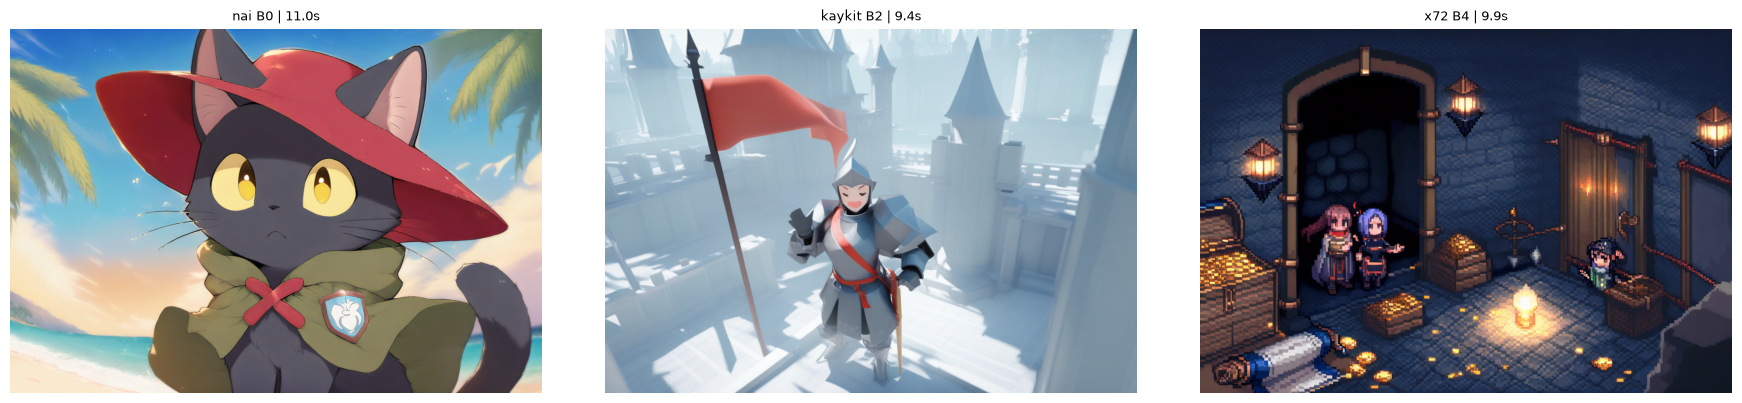

In [6]:
CHILD_C = r"""
from compel import CompelForSDXL
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

log('animagine 로드 시작')
t_load = time.perf_counter()
pipe = StableDiffusionXLPipeline.from_pretrained(a['model'], torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(a['ipa']['repo'], subfolder=a['ipa']['subfolder'], weight_name=a['ipa']['weight_name'])
pipe.to('cuda')
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
compel = CompelForSDXL(pipe)
load_sec = round(time.perf_counter() - t_load, 2)
peak_now()
log(f'animagine 로드 끝 {load_sec}초')
for k, t in enumerate(a['tasks'], 1):
    rec = dict(file=t['file'], error='')
    try:
        extra = 0.0
        if t['lora']:
            t2 = time.perf_counter()
            log('LoRA 불러오기 ' + t['lora'])
            pipe.load_lora_weights(t['lora'], weight_name='pytorch_lora_weights.safetensors', adapter_name='style')
            extra += time.perf_counter() - t2
        n_tok = len(pipe.tokenizer(t['prompt']).input_ids)
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        pipe.set_ip_adapter_scale(t['ipa_scale'])
        if t['compel']:
            e = compel(t['prompt'], negative_prompt=t['negative'])
            kw = dict(prompt_embeds=e.embeds, pooled_prompt_embeds=e.pooled_embeds, negative_prompt_embeds=e.negative_embeds,
                      negative_pooled_prompt_embeds=e.negative_pooled_embeds)
        else:
            kw = dict(prompt=t['prompt'], negative_prompt=t['negative'])
        img = pipe(**kw, ip_adapter_image=Image.open(t['ref']).convert('RGB'), width=a['w'], height=a['h'],
                   num_inference_steps=a['steps'], guidance_scale=a['cfg'], generator=torch.Generator('cpu').manual_seed(a['seed'])).images[0]
        img.save(t['out'])
        rec.update(sec=round(time.perf_counter() - t1, 2), peak_vram_gb=peak_now())
        if t['lora']:
            t2 = time.perf_counter()
            pipe.unload_lora_weights()
            extra += time.perf_counter() - t2
        rec.update(extra_sec=round(extra, 2), info=json.dumps(dict(n_tokens=n_tok, truncated=n_tok > pipe.tokenizer.model_max_length
                                                                   and not t['compel'])))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    write(rec)
    log(f"C {k}/{len(a['tasks'])} {t['file']} {rec.get('sec')}초 (LoRA {rec.get('extra_sec', 0)}초) {rec['error'][:100]}")
write_stage(load_sec)
"""

(IMG_DIR / 'c').mkdir(exist_ok=True)
C_FILE = {g: f'images/c/C__{g}.png' for g in GAME_GOODS}
todo = [g for g in GAME_GOODS if not img_done(C_FILE[g])]
log(f'C {len(todo)}장 / 전체 {len(GAME_GOODS)}장')
if todo:
    tasks = []
    for g in todo:
        c = C_GAMES[g]
        lora = str((NAI_LORA / '').resolve()) if g == 'nai' else ''
        tasks.append(dict(file=C_FILE[g], out=str((OUT_DIR / C_FILE[g]).resolve()), prompt=c_prompt(g), negative=c['negative'],
                          ipa_scale=c['ipa'], compel=c['compel'], ref=str(C_REFS[g].resolve()), lora=lora,
                          meta=dict(stage='c_image', game=g, kind='C', pages=json.dumps([f'{g}__{d}' for d in D_OPTS]), params=json.dumps(dict(
                              model=C_MODEL, item=C_ITEM[g], scene=C_SCENE[g], prompt=c_prompt(g), negative=c['negative'], ipa=c['ipa'],
                              ipa_name=c['ipa_name'], compel=c['compel'], lora=lora, seed=C_SEED, **C_GEN), ensure_ascii=False))))
    got, st = run_stage('c_image', CHILD_C, dict(model=C_MODEL, ipa=C_IPA, w=C_GEN['width'], h=C_GEN['height'], steps=C_GEN['steps'],
                                                 cfg=C_GEN['cfg'], seed=C_SEED, tasks=[{k: v for k, v in t.items() if k != 'meta'} for t in tasks]))
    finish_stage('c_image', C_MODEL + ' + IP-Adapter (+ nai LoRA)', tasks, got, st, IMG_RECS, 'file')

fig, axes = plt.subplots(1, len(GAME_GOODS), figsize=(6 * len(GAME_GOODS), 4))
for ax, g in zip(axes, GAME_GOODS):
    ax.axis('off')
    if img_done(C_FILE[g]):
        ax.imshow(Image.open(OUT_DIR / C_FILE[g]))
        ax.set_title(f"{g} {C_ITEM[g]} | {num(IMG_RECS[C_FILE[g]]['sec']):.1f}s", fontsize=9)
plt.tight_layout()
plt.show()

## 3단계: 빈 배경 (SDXL base, 별도 프로세스)

SDXL base img2img 파이프라인을 bf16으로 불러 `from_pipe`로 빈 배경(텍스트→이미지, 15 D2 배경과 같음)을 만든다. 11/02 처음 실행에서는 F0 3장도 별도 프로세스(`sdxl_f0`)로 만들었으나, F0은 그림이 거의 찍히지 않아 22 합성으로 바꾸고 이 단계에서 뺐다(다음 "3-2단계").

[12:13:13] SDXL 단계 빈 배경 0장


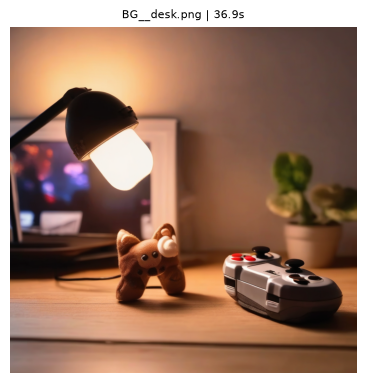

In [7]:
CHILD_SDXL = r"""
from diffusers import StableDiffusionXLImg2ImgPipeline, StableDiffusionXLPipeline

log('SDXL base 로드 시작')
t_load = time.perf_counter()
pipe = StableDiffusionXLImg2ImgPipeline.from_pretrained(a['model'], torch_dtype=torch.bfloat16).to('cuda')
pipe.set_progress_bar_config(disable=True)
load_sec = round(time.perf_counter() - t_load, 2)
peak_now()
log(f'SDXL base 로드 끝 {load_sec}초')
n = len(a['tasks'])
for k, t in enumerate(a['tasks'], 1):
    rec = dict(file=t['file'], error='')
    try:
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        b = a['bg']
        t2i = StableDiffusionXLPipeline.from_pipe(pipe)
        out = t2i(prompt=b['prompt'], negative_prompt=b['negative'], num_inference_steps=b['steps'], guidance_scale=b['cfg'],
                  width=b['size'], height=b['size'], generator=torch.Generator('cpu').manual_seed(b['seed'])).images[0]
        del t2i
        out.save(t['out'])
        rec.update(sec=round(time.perf_counter() - t1, 2), peak_vram_gb=peak_now())
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    write(rec)
    log(f"SDXL {k}/{n} {t['file']} {rec.get('sec')}초 {rec['error'][:100]}")
write_stage(load_sec)
"""

(IMG_DIR / 'bg').mkdir(exist_ok=True)
BG_FILE = f'images/bg/BG__{SCENE}.png'
tasks = []
if not img_done(BG_FILE):
    tasks.append(dict(file=BG_FILE, kind='BG', out=str((OUT_DIR / BG_FILE).resolve()), meta=dict(
        stage='sdxl_bg', game='all', kind='BG', pages=json.dumps([f'{g}__R1n' for g in GAME_GOODS]),
        params=json.dumps(dict(model=SDXL_BASE, **BG_ARGS), ensure_ascii=False))))
save_recs()
log(f'SDXL 단계 빈 배경 {len(tasks)}장')
if tasks:
    got, st = run_stage('sdxl_bg', CHILD_SDXL, dict(model=SDXL_BASE, bg=BG_ARGS, tasks=[{k: v for k, v in t.items() if k != 'meta'} for t in tasks]))
    finish_stage('sdxl_bg', SDXL_BASE + ' (빈 배경, 텍스트→이미지)', tasks, got, st, IMG_RECS, 'file')

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.axis('off')
if img_done(BG_FILE):
    ax.imshow(Image.open(OUT_DIR / BG_FILE))
    ax.set_title(f"{Path(BG_FILE).name} | {num(IMG_RECS[BG_FILE]['sec']):.1f}s", fontsize=8)
plt.show()

## 3-2단계: 굿즈 목업 후보 (22 합성, GPU 안 씀)

22 "합성 함수·14 F1 재현 확인" 셀의 합성 함수를 그대로 옮겨, 게임마다 굿즈 종류에 맞는 후보를 모두 만든다(머그 F1·F1curve·F1spec, 옷·에코백 F1·F1cloth). 서비스에서는 이 후보를 나란히 보여 주고 소비자가 하나를 고르므로, 후보를 모두 만드는 시간이 페이지의 목업 시간이다. 인쇄 영역과 머그 휨은 22 기록을 쓴다. 모델을 불러오지 않으므로 이 커널에서 바로 처리하고 단계 기록에 남긴다(`mockup`, 모델 로드 0초).

[12:13:14] 목업 후보 0장 / 전체 7장


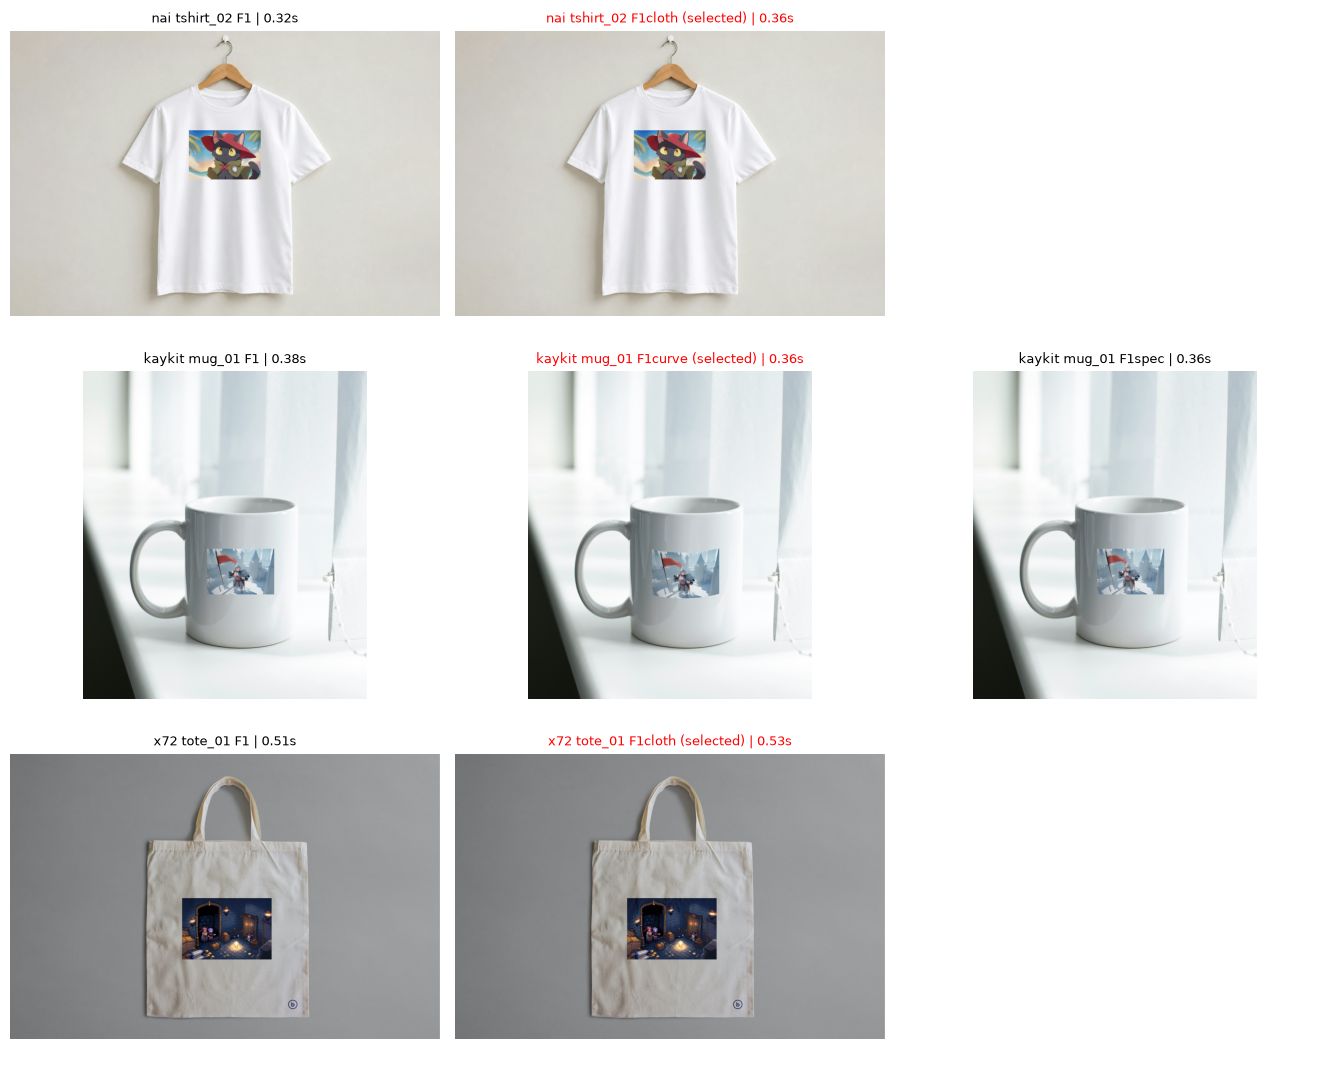

In [8]:
def load_goods(name):
    # 14와 같음: 원본 사진을 긴 변 1024(8의 배수)로 줄임
    im = Image.open(GOODS_DIR / name).convert('RGB')
    s = MAX_SIDE / max(im.size)
    return im.resize((int(round(im.width * s / 8)) * 8, int(round(im.height * s / 8)) * 8), Image.LANCZOS)


def load_mask(name):
    return np.asarray(Image.open(MASK_DIR / f'{Path(name).stem}.png')).astype(np.float32) / 255.0


# 22 합성 함수가 쓰는 이름: 굿즈 종류, 머그 휨 (22 mug_curve.csv)
KIND = {f: GOODS_KIND[g] for g, f in GAME_GOODS.items()}
CURVES = {f: dict(cx=float(F22_CURVE.cx[f]), half=float(F22_CURVE.half[f]), b=float(F22_CURVE.b[f]))
          for g, f in GAME_GOODS.items() if GOODS_KIND[g] == 'mug'}


def bilinear(img, yy, xx):
    h, w = img.shape[:2]
    yy, xx = np.clip(yy, 0, h - 1), np.clip(xx, 0, w - 1)
    y0, x0 = np.floor(yy).astype(int), np.floor(xx).astype(int)
    y1, x1 = np.minimum(y0 + 1, h - 1), np.minimum(x0 + 1, w - 1)
    wy, wx = (yy - y0)[..., None], (xx - x0)[..., None]
    return (img[y0, x0] * (1 - wy) * (1 - wx) + img[y0, x1] * (1 - wy) * wx + img[y1, x0] * wy * (1 - wx) + img[y1, x1] * wy * wx)


def compose(name, design_path, box, curve=False, spec=False, cloth=False):
    # 반환: (합성 이미지, 실제로 그린 높이). F1curve는 가운데가 내려간 만큼 영역이 아래로 늘어남
    img = load_goods(name)
    kind = KIND[name]
    x, y, w, h = box
    d = np.asarray(Image.open(design_path).convert('RGB').resize((w, h), Image.LANCZOS), dtype=np.float64)
    lift, H = None, h
    if curve:
        c = CURVES[name]
        us = np.clip((x + np.arange(w) + 0.5 - c['cx']) / c['half'], -1, 1)
        lift = c['b'] * np.sqrt(1 - us ** 2)
        lift = lift - lift.min()
        H = min(h + int(np.ceil(lift.max())), img.height - y)
    yy, xx = np.mgrid[0:H, 0:w].astype(np.float64)
    if kind == 'mug':
        # 원통 곡면: 화면 가로 위치 u → 그림 가로 위치 θ/θmax (가장자리일수록 눌림)
        u = (xx + 0.5) / w * 2 - 1
        xx = (np.arcsin(np.clip(u, -1, 1) * np.sin(MUG_HALF_ANGLE)) / MUG_HALF_ANGLE + 1) / 2 * w - 0.5
    if lift is not None:
        yy = yy - lift[None, :]
    gray_l = img.convert('L')
    gray_raw = np.asarray(gray_l, dtype=np.float64)[y:y + H, x:x + w]
    gray = np.asarray(gray_l.filter(ImageFilter.GaussianBlur(2)), dtype=np.float64)[y:y + H, x:x + w]
    region = load_mask(name)[y:y + H, x:x + w]
    inside = gray[region > 0.5] if (region > 0.5).any() else gray.ravel()
    lo, hi = np.percentile(inside, 2), np.percentile(inside, 98)
    ln = np.clip((gray - lo) / max(hi - lo, 1e-6), 0, 1)
    disp = (ln - 0.5) * DISP_RATIO * (CLOTH_DISP_MULT if cloth else 1) * w
    sy, sx = yy + disp, xx + disp
    # 휨으로 그림 밖을 가리키는 픽셀은 원본을 그대로 둠
    valid = ((sy >= -0.5) & (sy <= h - 0.5)).astype(np.float64) if lift is not None else 1.0
    warped = bilinear(d, sy, sx)
    shade = np.clip(gray / max(np.percentile(inside, 95), 1e-6), 0, 1)
    warped = warped * (1 - (1 - shade) * SHADE_BLEND)[..., None]
    if cloth:
        g = Image.fromarray(gray_raw.clip(0, 255).astype(np.uint8))
        detail = gray_raw - np.asarray(g.filter(ImageFilter.GaussianBlur(CLOTH_DETAIL_SIGMA)), dtype=np.float64)
        warped = warped + (detail * CLOTH_DETAIL)[..., None]
    if spec:
        # 큰 흐림보다 밝은 좁은 띠만 반사광으로 봄 (넓은 밝기 변화는 음영이 이미 반영)
        blur = np.asarray(gray_l.filter(ImageFilter.GaussianBlur(SPEC_SIGMA_RATIO * w)), dtype=np.float64)[y:y + H, x:x + w]
        hl = np.clip((gray - blur) / SPEC_RANGE, 0, 1)
        warped = warped + (255 - warped) * (hl * SPEC_BLEND)[..., None]
    a = np.asarray(img, dtype=np.float64).copy()
    alpha = (region * valid)[..., None]
    a[y:y + H, x:x + w] = a[y:y + H, x:x + w] * (1 - alpha) + warped.clip(0, 255) * alpha
    return Image.fromarray(a.clip(0, 255).astype(np.uint8)), H



(IMG_DIR / 'mockup').mkdir(exist_ok=True)
MOCK_FILE = {(g, c): f'images/mockup/{c}__{STEM[g]}__{g}.png' for g in GAME_GOODS for c in cands_of(g)}
todo = []
for (g, c), f in MOCK_FILE.items():
    name = GAME_GOODS[g]
    box = [int(F22_BOX.x[name]), int(F22_BOX.y[name]), int(F22_BOX.w[name]), int(F22_BOX.h[name])]
    params = json.dumps(dict(mock_params(c, GOODS_KIND[g]), goods=name, box=box, design=C_FILE[g]), ensure_ascii=False)
    if img_done(f) and IMG_RECS[f].get('params') == params:
        continue
    todo.append((g, c, f, box, params))
log(f'목업 후보 {len(todo)}장 / 전체 {len(MOCK_FILE)}장')
if todo:
    started, t_all, items, n_ok = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter(), 0.0, 0
    for i, (g, c, f, box, params) in enumerate(todo, 1):
        rec = dict(file=f, stage='mockup', game=g, kind=c, pages=json.dumps([f'{g}__{d}' for d in D_OPTS]), params=params, error='')
        if not img_done(C_FILE[g]):
            rec['error'] = 'C 이미지 없음 (2단계 실패)'
        else:
            try:
                t0 = time.perf_counter()
                im, H = compose(GAME_GOODS[g], OUT_DIR / C_FILE[g], box, **cands_of(g)[c])
                im.save(OUT_DIR / f)
                rec.update(sec=round(time.perf_counter() - t0, 3), box_h=H)
                items += rec['sec']
                n_ok += 1
            except Exception as e:
                rec['error'] = f'{type(e).__name__}: {e}'[:300]
        IMG_RECS[f] = rec
        log(f"목업 {i}/{len(todo)} {f} {rec.get('sec')}초 {rec['error'][:100]}", t_all)
    save_recs()
    wall = round(time.perf_counter() - t_all, 2)
    pd.DataFrame([dict(stage='mockup', model='22 합성 (numpy·Pillow)', started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                       n_items=len(todo), n_ok=n_ok, wall_sec=wall, import_sec=0.0, load_sec=0.0, extra_load_sec=0.0,
                       items_sec=round(items, 2), fixed_sec=round(wall - items, 2), item_sec_mean=round(items / n_ok, 3) if n_ok else None,
                       peak_vram_gb=0.0, returncode=0)]).to_csv(STAGE_CSV, mode='a', header=not STAGE_CSV.exists(), index=False,
                                                              encoding='utf-8-sig')

# 게임별 후보 (빨간 제목 = ③에 넣는 가상 예시 선택)
ncol = max(len(cands_of(g)) for g in GAME_GOODS)
fig, axes = plt.subplots(len(GAME_GOODS), ncol, figsize=(4.5 * ncol, 3.6 * len(GAME_GOODS)), squeeze=False)
for i, g in enumerate(GAME_GOODS):
    for j in range(ncol):
        axes[i, j].axis('off')
    for j, c in enumerate(cands_of(g)):
        f = MOCK_FILE[(g, c)]
        if img_done(f):
            axes[i, j].imshow(Image.open(OUT_DIR / f))
            chosen = c == MOCKUP_CHOICE[g]
            axes[i, j].set_title(f"{g} {STEM[g]} {c}{' (selected)' if chosen else ''} | {num(IMG_RECS[f]['sec']):.2f}s", fontsize=9,
                                 color='red' if chosen else 'black')
plt.tight_layout()
plt.show()

## 3-3단계: D 입력 (고객 사진 또는 고른 목업, BiRefNet 마스크, 별도 프로세스)

④ D 입력을 정하고 마스크와 틀을 계산한다. 고객 굿즈 사진(`D_CUSTOMER_PHOTO`)이 있으면 그 사진, 없으면 ③에서 고른 목업을 쓴다. BiRefNet을 한 번 불러 게임 3개를 처리하고, 항목마다 입력을 긴 변 1024로 줄이기 → 마스크 → 틀로 가운데 자르기까지를 그 항목 시간으로 기록한다. 입력이 바뀌면(목업 선택이나 고객 사진) 기록의 설정과 달라져 이 단계와 Y·IC-Light·합성을 다시 만든다.

[12:13:15] D 입력 마스크 0장 / 전체 3장


,game,source,error,sec,frame,mask_area,frame_rule,frame_16,frame_same_as_16,iou_vs_16
0,nai,mockup:images/mockup/F1cloth__tshirt_02__nai.png,,0.88,"[1024, 680]",0.2507,"[1024, 680]","[1024, 680]",True,0.9995
1,kaykit,mockup:images/mockup/F1curve__mug_01__kaykit.png,,0.46,"[952, 1024]",0.209,"[952, 1024]","[952, 1024]",True,0.9991
2,x72,mockup:images/mockup/F1cloth__tote_01__x72.png,,0.40,"[1024, 680]",0.2415,"[1024, 680]","[1024, 680]",True,0.9997


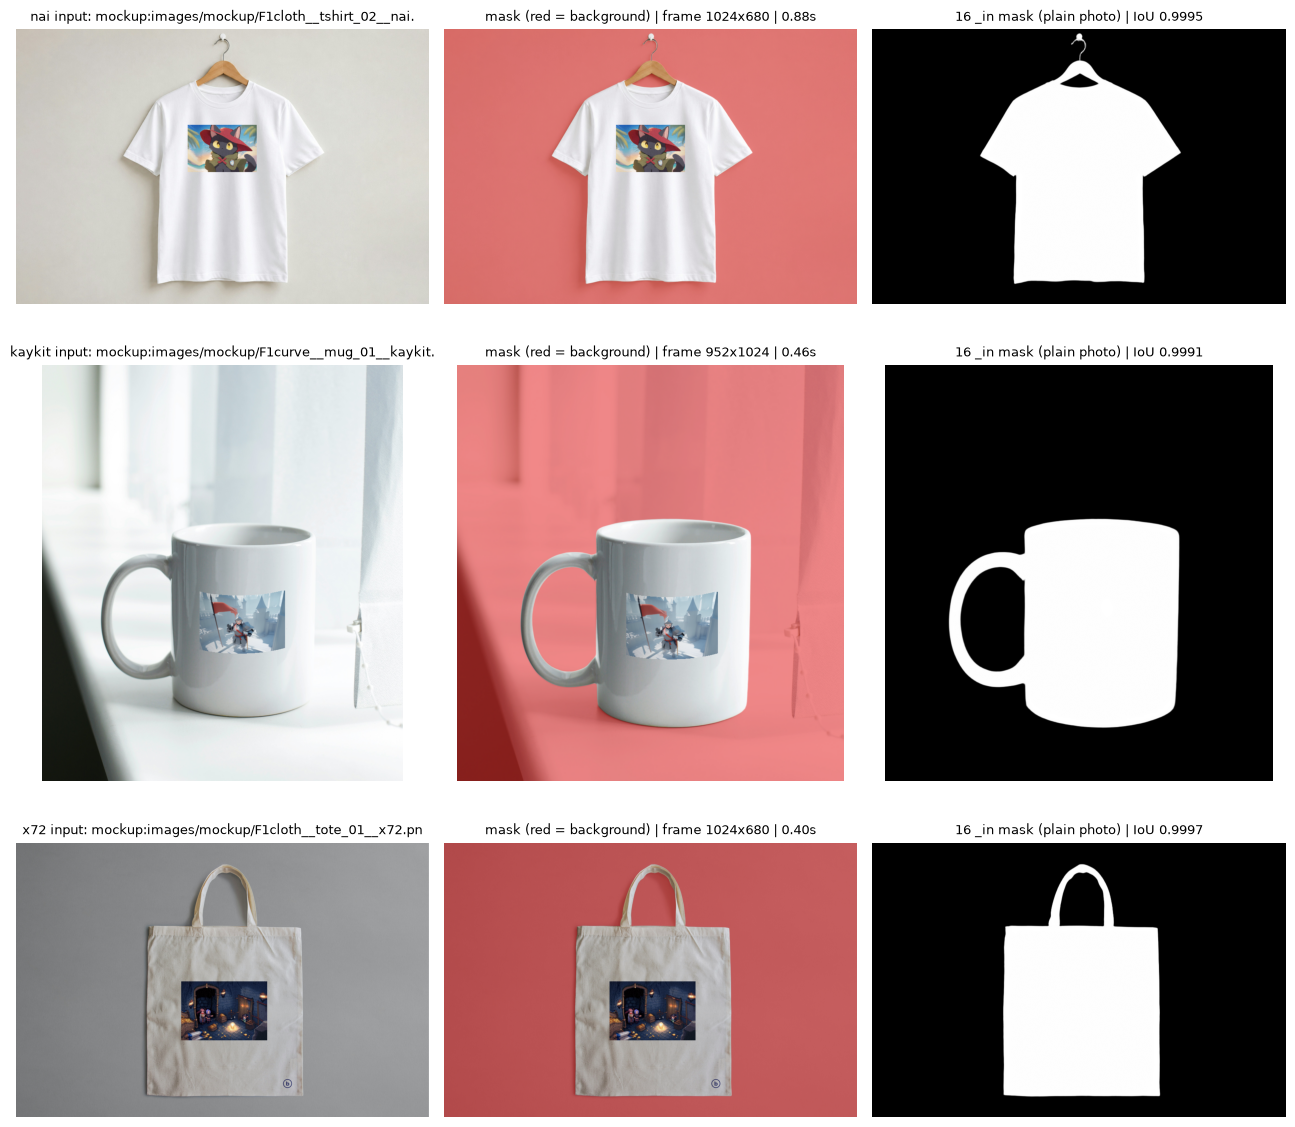

In [9]:
CHILD_MASK = r"""
from torchvision import transforms
from transformers import AutoModelForImageSegmentation


def center_crop(im, w, h):
    # IC-Light 데모 resize_and_center_crop과 같은 방식 (16과 같음)
    s = max(w / im.width, h / im.height)
    rw, rh = int(round(im.width * s)), int(round(im.height * s))
    im = im.resize((rw, rh), Image.LANCZOS)
    return im.crop(((rw - w) / 2, (rh - h) / 2, (rw + w) / 2, (rh + h) / 2))


def d_frame(w0, h0):
    f = a['frame']
    s = f['ic_max_side'] / max(w0, h0)
    w, h = int(round(w0 * s / 64)) * 64, int(round(h0 * s / 64)) * 64
    W, H = int(round(w * f['highres_scale'] / 64)) * 64, int(round(h * f['highres_scale'] / 64)) * 64
    s2 = f['max_side'] / max(W, H)
    return int(round(W * s2 / 8)) * 8, int(round(H * s2 / 8)) * 8


log('BiRefNet 로드 시작')
t_load = time.perf_counter()
model = AutoModelForImageSegmentation.from_pretrained(a['repo'], trust_remote_code=True).to('cuda').eval().float()
tf = transforms.Compose([transforms.Resize((1024, 1024)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
load_sec = round(time.perf_counter() - t_load, 2)
peak_now()
log(f'BiRefNet 로드 끝 {load_sec}초')
for k, t in enumerate(a['tasks'], 1):
    rec = dict(file=t['file'], error='')
    try:
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        im = Image.open(t['source_path']).convert('RGB')
        # 14 load_goods와 같음: 긴 변 1024(8의 배수). 목업은 이미 이 크기라 그대로
        s = a['frame']['max_side'] / max(im.size)
        img = im.resize((int(round(im.width * s / 8)) * 8, int(round(im.height * s / 8)) * 8), Image.LANCZOS)
        with torch.no_grad():
            pred = model(tf(img).unsqueeze(0).to('cuda'))[-1].sigmoid()[0, 0].float().cpu().numpy()
        m = Image.fromarray((pred * 255).astype(np.uint8)).resize(img.size, Image.BILINEAR)
        m.save(t['mask_full_out'])
        w, h = d_frame(*img.size)
        center_crop(img, w, h).save(t['goods_out'])
        cm = center_crop(m, w, h)
        cm.save(t['mask_out'])
        rec.update(sec=round(time.perf_counter() - t1, 2), peak_vram_gb=peak_now(), info=json.dumps(dict(
            source_size=list(im.size), in_size=list(img.size), frame=[w, h],
            mask_area=round(float((np.asarray(cm, dtype=np.float32) / 255 > 0.5).mean()), 4))))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    write(rec)
    log(f"마스크 {k}/{len(a['tasks'])} {t['file']} {rec.get('sec')}초 {rec['error'][:100]}")
write_stage(load_sec)
"""

(IMG_DIR / 'd_in' / 'full').mkdir(parents=True, exist_ok=True)
DIN_GOODS = {g: f'images/d_in/IN__{STEM[g]}__{SCENE}.png' for g in GAME_GOODS}
DIN_MASK = {g: f'images/d_in/IN__{STEM[g]}__{SCENE}_mask.png' for g in GAME_GOODS}


def d_source(g):
    # 고객 굿즈 사진이 있으면 그 사진, 없으면 ③에서 고른 목업
    if D_CUSTOMER_PHOTO[g]:
        return Path(D_CUSTOMER_PHOTO[g]), f'customer:{Path(D_CUSTOMER_PHOTO[g]).name}'
    return OUT_DIR / MOCK_FILE[(g, MOCKUP_CHOICE[g])], f'mockup:{MOCK_FILE[(g, MOCKUP_CHOICE[g])]}'


def d_in_params(g):
    return json.dumps(dict(model=BIREFNET, source=d_source(g)[1], max_side=MAX_SIDE, ic_max_side=D2_ARGS['max_side'],
                           highres_scale=D2_ARGS['highres_scale']), ensure_ascii=False)


def d_in_done(g):
    f = DIN_MASK[g]
    return img_done(f) and (OUT_DIR / DIN_GOODS[g]).exists() and IMG_RECS[f].get('params') == d_in_params(g)


todo = [g for g in GAME_GOODS if not d_in_done(g)]
log(f'D 입력 마스크 {len(todo)}장 / 전체 {len(GAME_GOODS)}장')
if todo:
    tasks = []
    for g in todo:
        src, label = d_source(g)
        meta = dict(stage='mask', game=g, kind='d_in', pages=json.dumps([f'{g}__{d}' for d in D_OPTS]), params=d_in_params(g),
                    source=label, goods_file=DIN_GOODS[g])
        if not src.exists():
            IMG_RECS[DIN_MASK[g]] = dict(meta, file=DIN_MASK[g], error=f'입력 없음: {label}')
            continue
        tasks.append(dict(file=DIN_MASK[g], source_path=str(src.resolve()), goods_out=str((OUT_DIR / DIN_GOODS[g]).resolve()),
                          mask_out=str((OUT_DIR / DIN_MASK[g]).resolve()),
                          mask_full_out=str((IMG_DIR / 'd_in' / 'full' / f'MASK__{STEM[g]}.png').resolve()), meta=meta))
    save_recs()
    if tasks:
        got, st = run_stage('mask', CHILD_MASK, dict(repo=BIREFNET, frame=dict(max_side=MAX_SIDE, ic_max_side=D2_ARGS['max_side'],
                                                                                highres_scale=D2_ARGS['highres_scale']),
                                                     tasks=[{k: v for k, v in t.items() if k != 'meta'} for t in tasks]))
        for x in got:
            if x.get('info'):
                x.update({k: json.dumps(v) if isinstance(v, list) else v for k, v in json.loads(x['info']).items()})
                del x['info']
        finish_stage('mask', BIREFNET, tasks, got, st, IMG_RECS, 'file')

# 확인: 틀 크기가 16 _in 규칙과 같은지, 새 마스크와 16 _in 마스크(무지 사진)의 IoU
rows = []
for g in GAME_GOODS:
    r = IMG_RECS.get(DIN_MASK[g], {})
    row = dict(game=g, source=r.get('source'), error=r.get('error'), sec=r.get('sec'), frame=r.get('frame'), mask_area=r.get('mask_area'))
    old_g, old_m = IN16_DIR / f'{STEM[g]}__{SCENE}.png', IN16_DIR / f'{STEM[g]}__{SCENE}_mask.png'
    if img_done(DIN_MASK[g]):
        new_m = np.asarray(Image.open(OUT_DIR / DIN_MASK[g]).convert('L'), dtype=np.float32) / 255 > 0.5
        row['frame_rule'] = list(d_frame(*Image.open(OUT_DIR / MOCK_FILE[(g, MOCKUP_CHOICE[g])]).size)) if not D_CUSTOMER_PHOTO[g] else None
        if old_m.exists():
            om = np.asarray(Image.open(old_m).convert('L'), dtype=np.float32) / 255 > 0.5
            row['frame_16'] = list(Image.open(old_g).size)
            row['frame_same_as_16'] = om.shape == new_m.shape
            if om.shape == new_m.shape:
                row['iou_vs_16'] = round(float((om & new_m).sum() / max((om | new_m).sum(), 1)), 4)
                IMG_RECS[DIN_MASK[g]]['iou_vs_16'] = row['iou_vs_16']
    rows.append(row)
save_recs()
display(pd.DataFrame(rows))

fig, axes = plt.subplots(len(GAME_GOODS), 3, figsize=(13, 4.2 * len(GAME_GOODS)), squeeze=False)
for i, g in enumerate(GAME_GOODS):
    for ax in axes[i]:
        ax.axis('off')
    if not img_done(DIN_MASK[g]):
        continue
    gi = Image.open(OUT_DIR / DIN_GOODS[g]).convert('RGB')
    mi = np.asarray(Image.open(OUT_DIR / DIN_MASK[g]).convert('L'), dtype=np.float32)[..., None] / 255
    over = (np.asarray(gi, dtype=np.float32) * (0.45 + 0.55 * mi) + np.array([230, 40, 40]) * 0.55 * (1 - mi)).clip(0, 255).astype(np.uint8)
    axes[i, 0].imshow(Image.open(d_source(g)[0]))
    axes[i, 0].set_title(f"{g} input: {IMG_RECS[DIN_MASK[g]].get('source', '')[:45]}", fontsize=9)
    axes[i, 1].imshow(over)
    axes[i, 1].set_title(f"mask (red = background) | frame {gi.width}x{gi.height} | {num(IMG_RECS[DIN_MASK[g]].get('sec')):.2f}s", fontsize=9)
    old_m = IN16_DIR / f'{STEM[g]}__{SCENE}_mask.png'
    if old_m.exists():
        axes[i, 2].imshow(Image.open(old_m), cmap='gray')
        axes[i, 2].set_title(f"16 _in mask (plain photo) | IoU {IMG_RECS[DIN_MASK[g]].get('iou_vs_16', float('nan'))}", fontsize=9)
plt.tight_layout()
plt.show()

## 4단계: Y 배경 (검은 띠면 다시 생성, 별도 프로세스)

16 Y 별도 프로세스 코드에 20의 띠 판정을 넣었다. 굿즈마다 seed 0으로 만들고, 최종 결과(패딩을 걷어 키우고 원본 굿즈를 덮은 것)에 띠가 있으면 seed 1, 2 순서로 다시 만든다. 다시 만든 시간까지 그 항목의 시간이다.

In [10]:
CHILD_Y = r"""
from PIL import ImageOps


def resize_with_padding(img, expected_size):
    # 모델 카드 코드 그대로
    img.thumbnail((expected_size[0], expected_size[1]))
    delta_width = expected_size[0] - img.size[0]
    delta_height = expected_size[1] - img.size[1]
    pad_width = delta_width // 2
    pad_height = delta_height // 2
    padding = (pad_width, pad_height, delta_width - pad_width, delta_height - pad_height)
    return ImageOps.expand(img, padding), padding


def band(path):
    # 20과 같음: 가장자리별 띠 폭(px)과 판정. 띠: 가장자리 EDGE_PX 밝기 평균 < DARK, 전체 평균 > 60
    x = np.asarray(Image.open(path).convert('L'), dtype=np.float32)
    cols, rows = x.mean(0), x.mean(1)
    out = dict(mean=round(float(x.mean()), 1))
    for side, v in [('left', cols), ('right', cols[::-1]), ('top', rows), ('bottom', rows[::-1])]:
        dark = v < a['dark']
        out[f'{side}_px'] = int(len(dark) if dark.all() else np.argmin(dark))
        out[f'{side}_band'] = bool(v[:a['edge_px']].mean() < a['dark'] and x.mean() > 60)
    out['band'] = any(out[f'{s}_band'] for s in ['left', 'right', 'top', 'bottom'])
    return out


# 저장소 pipeline.py(diffusers 0.27 기준)의 옛 경로 → 현재 diffusers의 같은 모듈
import diffusers.models.controlnets.multicontrolnet as _mc
sys.modules.setdefault('diffusers.pipelines.controlnet.multicontrolnet', _mc)
from diffusers import DiffusionPipeline

log('Y 로드 시작')
t_load = time.perf_counter()
pipe = DiffusionPipeline.from_pretrained(a['repo'], custom_pipeline=a['repo'], trust_remote_code=True).to('cuda')
pipe.set_progress_bar_config(disable=True)
load_sec = round(time.perf_counter() - t_load, 2)
peak_now()
log(f'Y 로드 끝 {load_sec}초 | {type(pipe).__name__}')
S = a['size']
for k, t in enumerate(a['tasks'], 1):
    rec = dict(file=t['file'], error='')
    try:
        goods = Image.open(t['goods_path']).convert('RGB')
        fg = Image.open(t['mask_path']).convert('L')
        img, pad = resize_with_padding(goods.copy(), (S, S))
        m, _ = resize_with_padding(fg.copy(), (S, S))
        mask = ImageOps.invert(m)
        al = np.asarray(fg, dtype=np.float32)[..., None] / 255
        torch.cuda.reset_peak_memory_stats()
        tries, total = [], 0.0
        for seed in a['seeds']:
            t1 = time.perf_counter()
            g = torch.Generator(device='cuda').manual_seed(seed)
            with torch.autocast('cuda'):
                out = pipe(prompt=t['prompt'], image=img, mask_image=mask, control_image=mask, num_images_per_prompt=1, generator=g,
                           num_inference_steps=a['steps'], guess_mode=a['guess_mode'],
                           controlnet_conditioning_scale=a['cond_scale']).images[0]
            out.save(t['raw_tpl'].format(seed=seed))
            # 패딩을 걷어내고 원래 틀로 키운 뒤 원본 굿즈를 마스크 알파로 다시 덮어씀
            box = (pad[0], pad[1], S - pad[2], S - pad[3])
            big = np.asarray(out.crop(box).resize(goods.size, Image.LANCZOS), dtype=np.float32)
            res = np.asarray(goods, dtype=np.float32) * al + big * (1 - al)
            p = t['try_tpl'].format(seed=seed)
            Image.fromarray(res.round().clip(0, 255).astype(np.uint8)).save(p)
            b = band(p)
            sec = round(time.perf_counter() - t1, 2)
            total += sec
            tries.append(dict(seed=seed, sec=sec, **b))
            log(f"Y {k}/{len(a['tasks'])} {t['file']} seed {seed} {sec}초 띠 {'있음' if b['band'] else '없음'}")
            if not b['band']:
                break
        # 띠 없는 첫 결과, 3번 모두 띠면 마지막 결과
        Image.open(t['try_tpl'].format(seed=tries[-1]['seed'])).save(t['out'])
        rec.update(sec=round(total, 2), peak_vram_gb=peak_now(), info=json.dumps(dict(
            tries=tries, n_tries=len(tries), used_seed=tries[-1]['seed'], band_final=tries[-1]['band'])))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    write(rec)
write_stage(load_sec)
"""

(IMG_DIR / 'y' / 'raw').mkdir(parents=True, exist_ok=True)
Y_FILE = {g: f'images/y/Y__{STEM[g]}__{SCENE}.png' for g in GAME_GOODS}


def y_params(g):
    # D 입력(마스크 단계 설정)이 바뀌면 Y도 다시 만듦 (11/03)
    return json.dumps(dict(Y_ARGS, repo=Y_REPO, seeds=Y_SEEDS, prompt=scene_prompt(GOODS_KIND[g]), input=DIN_GOODS[g],
                           d_input=IMG_RECS.get(DIN_MASK[g], {}).get('params')), ensure_ascii=False)


todo = [g for g in GAME_GOODS if not img_done(Y_FILE[g]) or IMG_RECS[Y_FILE[g]].get('params') != y_params(g)]
log(f'Y {len(todo)}장 / 전체 {len(GAME_GOODS)}장')
if todo:
    tasks = []
    for g in todo:
        st_ = f'{STEM[g]}__{SCENE}'
        meta = dict(stage='y', game=g, kind='Y', pages=json.dumps([f'{g}__YR1n']), params=y_params(g))
        if not d_in_done(g):
            IMG_RECS[Y_FILE[g]] = dict(meta, file=Y_FILE[g], error='D 입력 없음 (3-3단계 실패)')
            continue
        tasks.append(dict(file=Y_FILE[g], prompt=scene_prompt(GOODS_KIND[g]), goods_path=str((OUT_DIR / DIN_GOODS[g]).resolve()),
                          mask_path=str((OUT_DIR / DIN_MASK[g]).resolve()), out=str((OUT_DIR / Y_FILE[g]).resolve()),
                          try_tpl=str((IMG_DIR / 'y').resolve() / f'Y_s{{seed}}__{st_}.png'),
                          raw_tpl=str((IMG_DIR / 'y' / 'raw').resolve() / f'Y_s{{seed}}__{st_}.png'), meta=meta))
    save_recs()
if todo and tasks:
    got, st = run_stage('y', CHILD_Y, dict(repo=Y_REPO, seeds=Y_SEEDS, dark=DARK, edge_px=EDGE_PX, **Y_ARGS,
                                           tasks=[{k: v for k, v in t.items() if k != 'meta'} for t in tasks]))
    for x in got:
        if x.get('info'):
            d = json.loads(x['info'])
            x.update(n_tries=d['n_tries'], used_seed=d['used_seed'], band_final=d['band_final'], tries=json.dumps(d['tries']))
            del x['info']
    finish_stage('y', Y_REPO, tasks, got, st, IMG_RECS, 'file')

yr = pd.DataFrame([IMG_RECS[f] for f in Y_FILE.values() if f in IMG_RECS])
display(yr[['file', 'error', 'sec', 'n_tries', 'used_seed', 'band_final', 'tries']] if 'n_tries' in yr else yr)

[12:13:16] Y 0장 / 전체 3장


,file,error,sec,n_tries,used_seed,band_final,tries
0,images/y/Y__tshirt_02__desk.png,,5.24,2,1,False,"[{""seed"": 0, ""sec"": 3.02, ""mean"": 155.1, ""left_px"": 78, ""left_band"": true, ""right_px"": 0, ""right_band"": false, ""top_px"": 0, ""top_band"": false, ""bottom_px"": 0, ""bottom_band"": false, ""band"": true}, ..."
1,images/y/Y__mug_01__desk.png,,2.27,1,0,False,"[{""seed"": 0, ""sec"": 2.27, ""mean"": 149.0, ""left_px"": 0, ""left_band"": false, ""right_px"": 0, ""right_band"": false, ""top_px"": 0, ""top_band"": false, ""bottom_px"": 0, ""bottom_band"": false, ""band"": false}]"
2,images/y/Y__tote_01__desk.png,,4.43,2,1,False,"[{""seed"": 0, ""sec"": 2.23, ""mean"": 123.1, ""left_px"": 164, ""left_band"": true, ""right_px"": 0, ""right_band"": false, ""top_px"": 0, ""top_band"": false, ""bottom_px"": 0, ""bottom_band"": false, ""band"": true},..."


## 5단계: IC-Light 조명 (R1n·YR1n, 별도 프로세스)

IC-Light를 한 번 불러 6장(게임 3개 × D 방식 2개)을 처리한다. 항목마다 (b)는 Y 배경의 굿즈 자리를 메운 뒤(17 `fill_hole`) IC-Light에 넣고, IC-Light 결과의 밝기 분포를 원본 굿즈에 옮겨(16 R1n 식) 배경 위에 얹는다. 메우기·IC-Light·조명 옮기기 시간을 따로 기록하고 합을 그 항목 시간으로 쓴다.

[12:13:16] IC-Light 0장 / 전체 6장


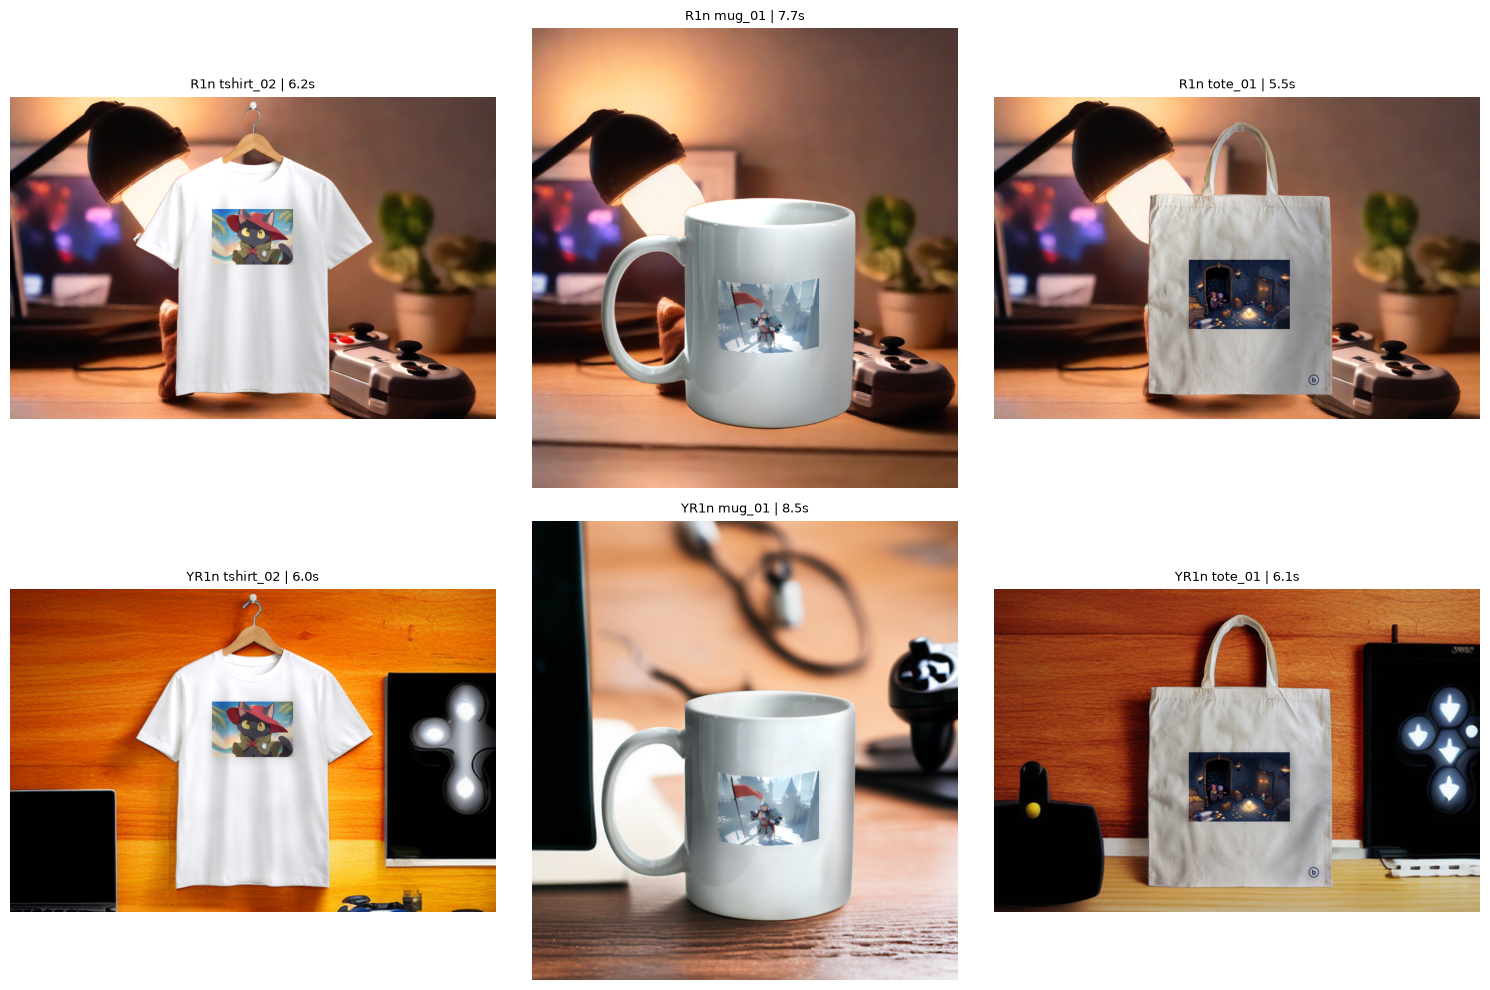

In [11]:
CHILD_IC = r"""
import math

import safetensors.torch as sf
import torch.nn.functional as F
from diffusers import AutoencoderKL, DPMSolverMultistepScheduler, StableDiffusionImg2ImgPipeline, StableDiffusionPipeline, UNet2DConditionModel
from diffusers.models.attention_processor import AttnProcessor2_0
from huggingface_hub import hf_hub_download
from PIL import ImageFilter
from transformers import CLIPTextModel, CLIPTokenizer

SD15, ICLIGHT = a['sd15'], a['iclight']
RATIO_CLIP = tuple(a['ratio_clip'])


# 15 "D2 IC-Light 배경 조건 재조명" 셀과 같은 코드 (IC-Light 공식 데모 gradio_demo_bg.py 커밋 bcf3f29)
def load_iclight():
    tokenizer = CLIPTokenizer.from_pretrained(SD15, subfolder='tokenizer')
    text_encoder = CLIPTextModel.from_pretrained(SD15, subfolder='text_encoder')
    vae = AutoencoderKL.from_pretrained(SD15, subfolder='vae')
    unet = UNet2DConditionModel.from_pretrained(SD15, subfolder='unet')
    with torch.no_grad():
        new_conv_in = torch.nn.Conv2d(12, unet.conv_in.out_channels, unet.conv_in.kernel_size, unet.conv_in.stride, unet.conv_in.padding)
        new_conv_in.weight.zero_()
        new_conv_in.weight[:, :4, :, :].copy_(unet.conv_in.weight)
        new_conv_in.bias = unet.conv_in.bias
        unet.conv_in = new_conv_in
    unet_original_forward = unet.forward

    def hooked_unet_forward(sample, timestep, encoder_hidden_states, **kwargs):
        c_concat = kwargs['cross_attention_kwargs']['concat_conds'].to(sample)
        c_concat = torch.cat([c_concat] * (sample.shape[0] // c_concat.shape[0]), dim=0)
        new_sample = torch.cat([sample, c_concat], dim=1)
        kwargs['cross_attention_kwargs'] = {}
        return unet_original_forward(new_sample, timestep, encoder_hidden_states, **kwargs)

    unet.forward = hooked_unet_forward
    sd_offset = sf.load_file(hf_hub_download(ICLIGHT['repo'], ICLIGHT['file']))
    sd_origin = unet.state_dict()
    unet.load_state_dict({k: sd_origin[k] + sd_offset[k] for k in sd_origin.keys()}, strict=True)
    del sd_offset, sd_origin
    text_encoder = text_encoder.to(device='cuda', dtype=torch.float16)
    vae = vae.to(device='cuda', dtype=torch.bfloat16)
    unet = unet.to(device='cuda', dtype=torch.float16)
    unet.set_attn_processor(AttnProcessor2_0())
    vae.set_attn_processor(AttnProcessor2_0())
    sched = DPMSolverMultistepScheduler(num_train_timesteps=1000, beta_start=0.00085, beta_end=0.012,
                                        algorithm_type='sde-dpmsolver++', use_karras_sigmas=True, steps_offset=1)
    kw = dict(vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet, scheduler=sched, safety_checker=None,
              requires_safety_checker=False, feature_extractor=None, image_encoder=None)
    return tokenizer, text_encoder, vae, StableDiffusionPipeline(**kw), StableDiffusionImg2ImgPipeline(**kw)


@torch.inference_mode()
def encode_prompt_inner(txt):
    max_length = tokenizer.model_max_length
    chunk_length = tokenizer.model_max_length - 2
    id_start, id_end = tokenizer.bos_token_id, tokenizer.eos_token_id

    def pad(x, p, i):
        return x[:i] if len(x) >= i else x + [p] * (i - len(x))

    tokens = tokenizer(txt, truncation=False, add_special_tokens=False)['input_ids']
    chunks = [[id_start] + tokens[i: i + chunk_length] + [id_end] for i in range(0, len(tokens), chunk_length)]
    chunks = [pad(ck, id_end, max_length) for ck in chunks]
    return text_encoder(torch.tensor(chunks).to(device='cuda', dtype=torch.int64)).last_hidden_state


@torch.inference_mode()
def encode_prompt_pair(positive_prompt, negative_prompt):
    c, uc = encode_prompt_inner(positive_prompt), encode_prompt_inner(negative_prompt)
    max_count = max(float(len(c)), float(len(uc)))
    max_chunk = max(len(c), len(uc))
    c = torch.cat([c] * int(math.ceil(max_count / len(c))), dim=0)[:max_chunk]
    uc = torch.cat([uc] * int(math.ceil(max_count / len(uc))), dim=0)[:max_chunk]
    return torch.cat([p[None, ...] for p in c], dim=1), torch.cat([p[None, ...] for p in uc], dim=1)


@torch.inference_mode()
def pytorch2numpy(imgs, quant=True):
    out = []
    for x in imgs:
        y = x.movedim(0, -1)
        if quant:
            out.append((y * 127.5 + 127.5).detach().float().cpu().numpy().clip(0, 255).astype(np.uint8))
        else:
            out.append((y * 0.5 + 0.5).detach().float().cpu().numpy().clip(0, 1).astype(np.float32))
    return out


@torch.inference_mode()
def numpy2pytorch(imgs):
    return (torch.from_numpy(np.stack(imgs, axis=0)).float() / 127.0 - 1.0).movedim(-1, 1)


def resize_and_center_crop(image, tw, th):
    pil = Image.fromarray(image)
    s = max(tw / pil.width, th / pil.height)
    rw, rh = int(round(pil.width * s)), int(round(pil.height * s))
    pil = pil.resize((rw, rh), Image.LANCZOS)
    return np.array(pil.crop(((rw - tw) / 2, (rh - th) / 2, (rw + tw) / 2, (rh + th) / 2)))


def resize_without_crop(image, tw, th):
    return np.array(Image.fromarray(image).resize((tw, th), Image.LANCZOS))


@torch.inference_mode()
def process(input_fg, input_bg, prompt, w, h, seed, steps, a_prompt, n_prompt, cfg, highres_scale, highres_denoise):
    rng = torch.Generator(device='cuda').manual_seed(seed)
    fg, bg = resize_and_center_crop(input_fg, w, h), resize_and_center_crop(input_bg, w, h)
    cc = vae.encode(numpy2pytorch([fg, bg]).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    cc = torch.cat([c[None, ...] for c in cc], dim=1)
    conds, unconds = encode_prompt_pair(prompt + ', ' + a_prompt, n_prompt)
    latents = t2i_pipe(prompt_embeds=conds, negative_prompt_embeds=unconds, width=w, height=h, num_inference_steps=steps,
                       num_images_per_prompt=1, generator=rng, output_type='latent', guidance_scale=cfg,
                       cross_attention_kwargs={'concat_conds': cc}).images.to(vae.dtype) / vae.config.scaling_factor
    pixels = pytorch2numpy(vae.decode(latents).sample)
    pixels = [resize_without_crop(p, int(round(w * highres_scale / 64.0) * 64), int(round(h * highres_scale / 64.0) * 64)) for p in pixels]
    latents = vae.encode(numpy2pytorch(pixels).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    latents = latents.to(device=t2i_pipe.unet.device, dtype=t2i_pipe.unet.dtype)
    h2, w2 = latents.shape[2] * 8, latents.shape[3] * 8
    fg, bg = resize_and_center_crop(input_fg, w2, h2), resize_and_center_crop(input_bg, w2, h2)
    cc = vae.encode(numpy2pytorch([fg, bg]).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    cc = torch.cat([c[None, ...] for c in cc], dim=1)
    latents = i2i_pipe(image=latents, strength=highres_denoise, prompt_embeds=conds, negative_prompt_embeds=unconds, width=w2,
                       height=h2, num_inference_steps=int(round(steps / highres_denoise)), num_images_per_prompt=1, generator=rng,
                       output_type='latent', guidance_scale=cfg,
                       cross_attention_kwargs={'concat_conds': cc}).images.to(vae.dtype) / vae.config.scaling_factor
    return pytorch2numpy(vae.decode(latents).sample, quant=False)[0]


def blur(x, sigma, pad='reflect'):
    # 분리형 가우시안 (x: H×W×C float), 17과 같음
    r = int(3 * sigma)
    k = torch.exp(-(torch.arange(-r, r + 1, dtype=torch.float32) ** 2) / (2 * sigma ** 2))
    k = k / k.sum()
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    t = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))[:, None].to(dev)
    k = k.to(dev)
    t = F.conv2d(F.pad(t, (r, r, 0, 0), mode=pad), k.view(1, 1, 1, -1))
    t = F.conv2d(F.pad(t, (0, 0, r, r), mode=pad), k.view(1, 1, -1, 1))
    return t[:, 0].cpu().numpy().transpose(1, 2, 0)


def masked_blur(x, al, sigma):
    # 굿즈 안쪽 값만으로 흐림 (정규화 합성곱), 16과 같음
    return blur(x * al[..., None], sigma) / np.maximum(blur(al[..., None], sigma), 1e-4)


def luma(x):
    return (x @ np.array([0.299, 0.587, 0.114], dtype=np.float32))[..., None]


def relight_n(goods, al, ic, sigma):
    # 16 R1n과 같은 식: 밝기 비율을 굿즈 안(알파 가중) 평균으로 나눠 전체 밝기는 원본 유지
    ratio = (masked_blur(luma(ic), al, sigma) + 1e-3) / (masked_blur(luma(goods), al, sigma) + 1e-3)
    mean = float((ratio[..., 0] * al).sum() / max(al.sum(), 1e-6))
    return (goods * np.clip(ratio / mean, *RATIO_CLIP)).clip(0, 1)


def fill_hole(img, al):
    # 17과 같음: 굿즈 자리(마스크 넓힘)를 주변 배경으로 메움 (1/8 크기에서 작은 흐림부터 큰 흐림 순으로 값이 있는 곳을 채움)
    hole = np.asarray(Image.fromarray(((al > 0.5) * 255).astype(np.uint8)).filter(
        ImageFilter.MaxFilter(2 * a['fill_dilate_px'] + 1)), dtype=np.float32) / 255
    h, w = hole.shape
    sw, sh = max(w // 8, 8), max(h // 8, 8)
    small = np.asarray(Image.fromarray((img * 255).astype(np.uint8)).resize((sw, sh), Image.BOX), dtype=np.float32) / 255
    keep = 1 - np.asarray(Image.fromarray((hole * 255).astype(np.uint8)).resize((sw, sh), Image.BOX), dtype=np.float32) / 255
    keep = (keep > 0.99).astype(np.float32)
    est, have = small * keep[..., None], keep.copy()
    for s in [1, 2, 4, 8, 16, 32]:
        den = blur(keep[..., None], s, pad='replicate')[..., 0]
        e = blur(small * keep[..., None], s, pad='replicate') / np.maximum(den, 1e-6)[..., None]
        new = (have == 0) & (den > 0.02)
        est[new], have[new] = e[new], 1
    # 채운 순서에 따라 생기는 계단 무늬를 줄이려고 메운 부분만 한 번 더 흐림
    est = np.where(keep[..., None] > 0, est, blur(est, 3, pad='replicate'))
    big = np.asarray(Image.fromarray((est.clip(0, 1) * 255).round().astype(np.uint8)).resize((w, h), Image.BICUBIC),
                     dtype=np.float32) / 255
    m = np.asarray(Image.fromarray((hole * 255).astype(np.uint8)).filter(ImageFilter.GaussianBlur(4)), dtype=np.float32)[..., None] / 255
    return img * (1 - m) + big * m


def arr(p):
    return np.asarray(Image.open(p).convert('RGB'), dtype=np.float32) / 255


log('IC-Light 로드 시작')
t_load = time.perf_counter()
tokenizer, text_encoder, vae, t2i_pipe, i2i_pipe = load_iclight()
t2i_pipe.set_progress_bar_config(disable=True)
i2i_pipe.set_progress_bar_config(disable=True)
load_sec = round(time.perf_counter() - t_load, 2)
peak_now()
log(f'IC-Light 로드 끝 {load_sec}초')
D = a['d2']
for k, t in enumerate(a['tasks'], 1):
    rec = dict(file=t['file'], error='')
    try:
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        goods = arr(t['goods_path'])
        al = np.asarray(Image.open(t['mask_path']).convert('L'), dtype=np.float32) / 255
        fill_sec = 0.0
        if t['opt'] == 'YR1n':
            ybg = arr(t['y_path'])
            cond = fill_hole(ybg, al)
            Image.fromarray((cond * 255).round().clip(0, 255).astype(np.uint8)).save(t['fill_out'])
            fill_sec = time.perf_counter() - t1
        else:
            cond = arr(t['bg_path'])
        t2 = time.perf_counter()
        h0, w0 = al.shape
        s = D['max_side'] / max(w0, h0)
        w, h = int(round(w0 * s / 64)) * 64, int(round(h0 * s / 64)) * 64
        # 데모 run_rmbg와 같은 회색(127) 배경 전경 (15·17과 같음)
        fg = (127 + (goods * 255 - 127) * al[..., None]).clip(0, 255).astype(np.uint8)
        res = process(fg, (cond * 255).round().astype(np.uint8), t['prompt'], w, h, a['seed'], D['steps'], D['a_prompt'], D['n_prompt'],
                      D['cfg'], D['highres_scale'], D['highres_denoise'])
        Image.fromarray((res * 255).clip(0, 255).astype(np.uint8)).save(t['ic_out'])
        ic_sec = time.perf_counter() - t2
        t3 = time.perf_counter()
        ic = np.asarray(Image.open(t['ic_out']).convert('RGB').resize((w0, h0), Image.LANCZOS), dtype=np.float32) / 255
        fgr = relight_n(goods, al, ic, t['sigma'])
        base = ic if t['base'] == 'ic' else ybg
        am = al[..., None]
        Image.fromarray(((fgr * am + base * (1 - am)) * 255).round().clip(0, 255).astype(np.uint8)).save(t['out'])
        rel_sec = time.perf_counter() - t3
        rec.update(sec=round(time.perf_counter() - t1, 2), peak_vram_gb=peak_now(), info=json.dumps(dict(
            fill_sec=round(fill_sec, 2), ic_sec=round(ic_sec, 2), relight_sec=round(rel_sec, 2), ic_w=w, ic_h=h)))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    write(rec)
    log(f"IC-Light {k}/{len(a['tasks'])} {t['file']} {rec.get('sec')}초 {rec['error'][:100]}")
write_stage(load_sec)
"""

for sub in ['ic', 'fill', 'd']:
    (IMG_DIR / sub).mkdir(exist_ok=True)
D_FILE = {(g, d): f'images/d/{d}__{STEM[g]}__{SCENE}.png' for g in GAME_GOODS for d in D_OPTS}


def ic_params(g, d):
    # D 입력이나 (b)의 Y가 바뀌면 다시 만듦 (11/03)
    return json.dumps(dict(
        D_CFG[d], prompt=scene_prompt(GOODS_KIND[g]), sd15=SD15, iclight=ICLIGHT, **D2_ARGS, seed=IC_SEED, ratio_clip=RATIO_CLIP,
        fill_dilate_px=FILL_DILATE_PX if d == 'YR1n' else None, input=DIN_GOODS[g], d_input=IMG_RECS.get(DIN_MASK[g], {}).get('params'),
        y_used=IMG_RECS.get(Y_FILE[g], {}).get('params') if d == 'YR1n' else None), ensure_ascii=False)


tasks = []
for (g, d), f in D_FILE.items():
    if img_done(f) and IMG_RECS[f].get('params') == ic_params(g, d):
        continue
    st_ = f'{STEM[g]}__{SCENE}'
    meta = dict(stage='iclight', game=g, kind=d, pages=json.dumps([f'{g}__{d}']), params=ic_params(g, d))
    up = BG_FILE if d == 'R1n' else Y_FILE[g]
    miss = [x for x in [up, DIN_MASK[g]] if not img_done(x)]
    if miss:
        IMG_RECS[f] = dict(meta, file=f, error=f'입력 없음: {miss}')
        continue
    tasks.append(dict(file=f, opt=d, sigma=D_CFG[d]['sigma'], base=D_CFG[d]['base'], prompt=scene_prompt(GOODS_KIND[g]),
                      goods_path=str((OUT_DIR / DIN_GOODS[g]).resolve()), mask_path=str((OUT_DIR / DIN_MASK[g]).resolve()),
                      bg_path=str((OUT_DIR / BG_FILE).resolve()), y_path=str((OUT_DIR / Y_FILE[g]).resolve()),
                      fill_out=str((IMG_DIR / 'fill' / f'FILL__{st_}.png').resolve()), ic_out=str((IMG_DIR / 'ic' / f'IC_{d}__{st_}.png').resolve()),
                      out=str((OUT_DIR / f).resolve()), meta=meta))
save_recs()
log(f'IC-Light {len(tasks)}장 / 전체 {len(D_FILE)}장')
if tasks:
    got, st = run_stage('iclight', CHILD_IC, dict(
        sd15=SD15, iclight=ICLIGHT, d2=D2_ARGS, seed=IC_SEED, ratio_clip=RATIO_CLIP, fill_dilate_px=FILL_DILATE_PX,
        tasks=[{k: v for k, v in t.items() if k != 'meta'} for t in tasks]))
    for x in got:
        if x.get('info'):
            x.update(json.loads(x['info']))
            del x['info']
    finish_stage('iclight', f'{SD15} + {ICLIGHT["file"]}', tasks, got, st, IMG_RECS, 'file')

fig, axes = plt.subplots(len(D_OPTS), len(GAME_GOODS), figsize=(5 * len(GAME_GOODS), 5 * len(D_OPTS)), squeeze=False)
for i, d in enumerate(D_OPTS):
    for j, g in enumerate(GAME_GOODS):
        ax = axes[i, j]
        ax.axis('off')
        f = D_FILE[(g, d)]
        if img_done(f):
            ax.imshow(Image.open(OUT_DIR / f))
            ax.set_title(f"{d} {STEM[g]} | {num(IMG_RECS[f]['sec']):.1f}s", fontsize=9)
plt.tight_layout()
plt.show()

## 6단계: 상세페이지 합성 (HTML → PNG, 26 2번)

26 2번 방식으로 페이지를 짜고 Chromium으로 찍는다. 코드는 앱 `src/app/core/page_html.py`와 같다. 이 셀이 코드를 `_child/page_html21.py`로 저장하고, 별도 프로세스가 Chromium을 한 번 띄워 6장을 차례로 찍는다(Jupyter 안에서는 Playwright 동기 API를 쓸 수 없음).

- 문구가 규칙을 끝내 통과하지 못해도(기록의 `rule_pass` False) 최종 문구를 그대로 넣는다. JSON으로 읽을 수 없으면 받은 글 전체를 넣는다.
- 제목은 3줄 안에 들도록 56px → 30px까지 줄이고, 구매 정보 값은 2줄 안에 들도록 21px → 15px까지 줄인다. 일러스트가 4장 이상이면 2열 격자로 넣는다(26).
- 11/03까지의 Pillow 합성(07 `compose`로 제목, 흰 글상자 4개)은 11/04 이 방식으로 바꿨다. 이전 페이지 기록은 `dp_image_records.csv`의 이전 실행 값으로 남지 않고 덮인다.

In [12]:
# 26 2번(HTML → PNG) 합성 코드: 앱 src/app/core/page_html.py와 같은 내용
PAGE_HTML_CODE = r'''# 상세 페이지 합성 (26 2번 방식): HTML·CSS로 짜고 Chromium으로 찍음. 26에서 극단 입력 30개 자동 검사 문제 0건, 이모지도 그림
import colorsys
import html
import time
from pathlib import Path

import numpy as np
from PIL import Image

W, PAD = 860, 64          # 상세 페이지 가로 860px (21과 같음), 좌우 여백
CW = W - 2 * PAD
DEFAULT_HUE = 0.6         # 색이 거의 없는 그림일 때 쓰는 기본 남색
SAT_MIN, SAT_SHARE = 0.12, 0.08  # 채도 0.12 넘는 픽셀이 8% 미만이면 기본 남색 (26)


def theme(img):
    # 대표 그림에서 채도 있는 픽셀의 색상(hue) 최빈값을 테마 색으로 씀
    a = np.asarray(img.convert('RGB').resize((128, 128))).reshape(-1, 3) / 255.0
    hsv = np.array([colorsys.rgb_to_hsv(*p) for p in a])
    sel = hsv[hsv[:, 1] > SAT_MIN]
    if len(sel) / len(hsv) < SAT_SHARE:
        h, src = DEFAULT_HUE, 'default'
    else:
        hist, e = np.histogram(sel[:, 0], bins=24, range=(0, 1))
        h, src = (e[hist.argmax()] + e[hist.argmax() + 1]) / 2, 'image'
    rgb = lambda s, v: tuple(int(x * 255) for x in colorsys.hsv_to_rgb(h, s, v))
    return dict(bg=rgb(.6, .09), bg2=rgb(.55, .16), accent=rgb(.45, .98), line=rgb(.5, .6), ink=(232, 241, 247), sub=(157, 179, 194),
                hue=round(float(h), 3), source=src)


def hexc(c):
    return '#%02x%02x%02x' % c


CSS = """
*{box-sizing:border-box;margin:0;padding:0}
body{width:%(W)dpx;background:var(--bg);color:var(--ink);font-family:"Malgun Gothic","Noto Sans CJK KR","Noto Color Emoji","Segoe UI Emoji",sans-serif;
  word-break:keep-all;overflow-wrap:anywhere}
.hero{position:relative;min-height:640px;display:flex;flex-direction:column;justify-content:flex-end;padding:300px 64px 56px;overflow:hidden}
.hero>img{position:absolute;inset:0;width:100%%;height:100%%;object-fit:cover}
.hero::after{content:"";position:absolute;inset:0;background:linear-gradient(0deg,var(--bg) 0,var(--bgA) var(--block),transparent var(--fade))}
.hero .txt{position:relative;z-index:2;text-align:center}
.eyebrow{display:inline-block;max-width:100%%;font-size:15px;line-height:1.5;letter-spacing:.3em;color:var(--accent);font-weight:700;padding:4px 18px;border:1px solid var(--line);border-radius:16px;background:var(--bg)}
.hero h1{margin-top:18px;font-size:56px;line-height:1.22;font-weight:900;color:#fff;text-shadow:0 0 18px var(--glow),0 4px 0 rgba(0,0,0,.6)}
.hero .info{margin-top:12px;font-size:19px;line-height:1.5;color:var(--sub)}
section{padding:0 64px;text-align:center;position:relative}
.head{padding-top:0;height:190px;position:relative}
.head::before{content:"";position:absolute;top:0;left:50%%;width:1px;height:44px;background:var(--line)}
.label{position:absolute;top:73px;left:0;right:0;font-size:14px;letter-spacing:.4em;color:var(--accent);font-weight:700}
.head h2{position:absolute;top:100px;left:0;right:0;font-size:36px;line-height:48px;font-weight:900;color:#fff}
.bar{position:absolute;top:160px;left:50%%;width:56px;height:4px;margin-left:-28px;background:var(--accent);box-shadow:0 0 12px var(--accent)}
p.body{margin:0 auto;font-size:20px;line-height:1.85}
.quote{margin:32px auto 0;max-width:620px;padding:22px 10px;font-size:21px;line-height:1.6;font-weight:700;color:var(--accent);border-top:1px solid var(--line);border-bottom:1px solid var(--line)}
.card{margin:36px auto 0;padding:10px;border:1px solid var(--line);border-radius:14px;background:var(--bg2);box-shadow:0 0 40px var(--glow2)}
.card img{display:block;width:100%%;max-height:var(--maxh);object-fit:contain;border-radius:8px}
.grid{margin:14px auto 0;display:flex;flex-wrap:wrap;justify-content:center;gap:12px}
.grid div{overflow:hidden;border:1px solid var(--line);border-radius:10px;background:var(--bg2)}
.grid img{width:100%%;height:100%%;object-fit:cover;display:block}
.slant{margin:40px auto 0;height:420px;display:flex;justify-content:center}
.slant div{height:100%%;position:relative;flex:none}
.slant img{width:100%%;height:100%%;object-fit:cover;display:block}
.slant .edge{position:absolute;inset:0;background:var(--accent)}
.full{margin:36px -64px 0}
.full img{display:block;width:100%%;max-height:900px;object-fit:contain;-webkit-mask-image:linear-gradient(180deg,transparent 0,#000 12%%,#000 88%%,transparent 100%%)}
.tiles{margin-top:36px;display:flex;flex-direction:column;gap:14px}
.row{display:flex;gap:14px}
.tile{flex:1 1 0;min-width:0;padding:14px 12px 20px;border:1px solid var(--line);border-radius:12px;background:var(--bg2)}
.tile .k{font-size:14px;line-height:1.5;color:var(--sub)}
.tile .v{margin-top:6px;font-size:21px;line-height:1.4;font-weight:700;color:#fff}
.note{margin-top:14px;font-size:13px;color:var(--sub)}
.cta{display:inline-block;margin:40px 0 50px;padding:18px 54px;font-size:21px;font-weight:900;color:var(--bg);background:var(--accent);border-radius:999px;box-shadow:0 0 24px var(--glow);text-decoration:none}
.url{margin:-34px auto 50px;max-width:640px;font-size:14px;line-height:1.5;color:var(--sub);word-break:break-all}
.soon{display:inline-block;margin:40px 0 50px;padding:14px 44px;font-size:20px;font-weight:800;letter-spacing:.08em;color:var(--accent);border:2px solid var(--accent);border-radius:999px}
"""

FIT_JS = """
() => {
  // 제목: 3줄 안에 드는 가장 큰 크기(56→30px), 이름표: 2줄 안(15→11px), 구매 정보 값: 2줄 안(21→15px)
  const fitEl = (el, big, small, maxLines, lh) => {
    for (let s = big; s >= small; s -= 2) { el.style.fontSize = s + 'px'; if (el.offsetHeight <= s * lh * maxLines + 1) return; }
    el.style.fontSize = small + 'px';
  };
  const h1 = document.querySelector('.hero h1'); if (h1) fitEl(h1, 56, 30, 3, 1.22);
  const eb = document.querySelector('.eyebrow'); if (eb) fitEl(eb, 15, 11, 2, 1.5);
  document.querySelectorAll('.tile .v').forEach(v => fitEl(v, 21, 15, 2, 1.4));
  // 첫 화면 그라데이션: 글자 덩어리 위로 220px부터 어두워지게
  const hero = document.querySelector('.hero'), txt = document.querySelector('.hero .txt');
  hero.style.setProperty('--block', (txt.offsetHeight + 56) + 'px');
  hero.style.setProperty('--fade', (txt.offsetHeight + 56 + 220) + 'px');
}
"""

SECTIONS_JS = """
() => [...document.querySelectorAll('.hero, section')].map(e => {
  const h = e.querySelector('h2'); const b = e.getBoundingClientRect();
  return {name: h ? h.textContent : '대표 그림 + 제목', y0: Math.round(b.top + scrollY), y1: Math.round(b.bottom + scrollY)}; })
"""

E = html.escape


def img_tag(p):
    return f'<img src="{Path(p).resolve().as_uri()}">'


def build_html(spec):
    # spec: hero, eyebrow, title, info, intro(문장 목록), sns, shot(없으면 None), refs, illus, mockup, mock_text, d, d_text, purchase, cta('none'·'buy'·'soon'), buy_url
    T = theme(Image.open(spec['hero']))
    v = {k: hexc(T[k]) for k in ['bg', 'bg2', 'accent', 'line', 'ink', 'sub']}
    a = T['accent']
    root = (':root{' + ';'.join(f'--{k}:{c}' for k, c in v.items()) +
            f';--glow:rgba({a[0]},{a[1]},{a[2]},.75);--glow2:rgba({a[0]},{a[1]},{a[2]},.18);--bgA:rgba({T["bg"][0]},{T["bg"][1]},{T["bg"][2]},.75)' + '}')
    h = [f'<!DOCTYPE html><html lang="ko"><head><meta charset="utf-8"><style>{root}{CSS % {"W": W}}</style></head><body>']
    h.append(f'<div class="hero">{img_tag(spec["hero"])}<div class="txt">' +
             (f'<span class="eyebrow">{E(spec["eyebrow"])}</span>' if spec['eyebrow'] else '') +
             (f'<h1>{E(spec["title"])}</h1>' if spec['title'] else '') +
             (f'<div class="info">{E(spec["info"])}</div>' if spec['info'] else '') + '</div></div>')
    head = lambda lab, t: f'<div class="head"><div class="label">{lab}</div><h2>{t}</h2><div class="bar"></div></div>'
    if spec['intro'] or spec['sns']:
        h.append('<section>' + head('ABOUT THE GAME', '게임 소개') +
                 (f'<p class="body" style="max-width:600px;padding-top:24px">{E(" ".join(spec["intro"]))}</p>' if spec['intro'] else '') +
                 (f'<div class="quote">“{E(spec["sns"])}”</div>' if spec['sns'] else '') + '<div style="height:40px"></div></section>')
    if spec['shot'] or spec['refs']:
        s = '<section>' + head('GAME SCREENS', '게임 화면')
        if spec['shot']:
            s += f'<div class="card" style="--maxh:900px">{img_tag(spec["shot"])}</div>'
        if spec['refs']:
            cols = min(4, len(spec['refs']))
            tw = min(240, (CW - 12 * (cols - 1)) // cols)
            s += f'<div class="grid" style="max-width:{cols * tw + (cols - 1) * 12}px">' + ''.join(
                f'<div style="width:{tw}px;height:{tw}px">{img_tag(p)}</div>' for p in spec['refs']) + '</div>'
        h.append(s + '<div style="height:50px"></div></section>')
    n = len(spec['illus'])
    if n:
        s = '<section>' + head('ILLUSTRATION', '일러스트')
        if n >= 4:  # 4장부터 2열 격자 (기울인 칸은 3장까지만 페이지 안에 들어감, 26)
            tw = (CW - 14) // 2
            s += f'<div class="grid" style="max-width:{CW}px;gap:14px">' + ''.join(
                f'<div style="width:{tw}px;height:{int(tw * 10 / 16)}px">{img_tag(p)}</div>' for p in spec['illus']) + '</div>'
        else:
            ov = 100 if n > 1 else 0
            pw = min(330 if n > 1 else 520, (W - 48 + ov * (n - 1)) // n)
            k = 28 if n > 1 else 12
            poly = f'polygon({k}% 0,100% 0,{100 - k}% 100%,0 100%)'
            edge = f'polygon({k}% 0,{k + 1.2}% 0,1.2% 100%,0 100%)'
            s += '<div class="slant" style="margin-left:-64px;margin-right:-64px">' + ''.join(
                f'<div style="width:{pw}px;margin-left:{-ov if i else 0}px;clip-path:{poly}">{img_tag(p)}<span class="edge" style="clip-path:{edge}"></span></div>'
                for i, p in enumerate(spec['illus'])) + '</div>'
        h.append(s + '<div style="height:40px"></div></section>')
    h.append('<section>' + head('GOODS DESIGN', '굿즈 디자인') + f'<div class="card" style="width:640px;--maxh:820px">{img_tag(spec["mockup"])}</div>' +
             (f'<p class="body" style="max-width:640px;margin-top:36px">{E(spec["mock_text"])}</p>' if spec['mock_text'] else '') +
             '<div style="height:40px"></div></section>')
    h.append('<section>' + head('ON YOUR DESK', '연출 사진') + f'<div class="full">{img_tag(spec["d"])}</div>' +
             (f'<p class="body" style="max-width:680px;margin-top:16px">{E(spec["d_text"])}</p>' if spec['d_text'] else '') +
             '<div style="height:40px"></div></section>')
    vals = {k: x for k, x in spec['purchase'].items() if str(x).strip()} or {'구매 정보': '(입력 없음)'}
    wide = [k for k in vals if k in ('상품명', '출고', '구매 정보')]
    small = [k for k in vals if k not in wide]
    rows = [[k] for k in wide[:1]] + ([small] if small else []) + [[k] for k in wide[1:]]
    tiles = ''.join('<div class="row">' + ''.join(f'<div class="tile"><div class="k">{E(k)}</div><div class="v">{E(str(vals[k]))}</div></div>' for k in r) + '</div>'
                    for r in rows)
    # 맨 아래는 사용자가 고른 것만 그린다(11/05 결정, 기본 'none'). 'buy'는 구매 링크가 있어야 하고 page.html에서는 눌리며 PNG에는 주소를 글자로 남긴다.
    # 'soon'은 누르는 것이 아니므로 버튼이 아닌 테두리 꼬리표로 그린다. cta가 없는 예전 사양은 링크가 있으면 'buy'로 본다
    url = str(spec.get('buy_url') or '').strip()
    kind = spec.get('cta') or ('buy' if url else 'none')
    if kind == 'buy' and url:
        cta = f'<a class="cta" href="{E(url)}" target="_blank" rel="noopener">굿즈 구매하러 가기 ›</a><div class="url">{E(url)}</div>'
    elif kind == 'soon':
        cta = '<div class="soon">출시 예정</div>'
    else:
        cta = '<div style="height:50px"></div>'
    h.append('<section>' + head('GOODS INFO', '굿즈 구매 정보') + f'<div class="tiles">{tiles}</div>' +
             (f'<div class="note">{E(spec["note"])}</div>' if spec.get('note') else '') + cta + '</section>')
    h.append('</body></html>')
    return ''.join(h), T


def render(spec, out_png, out_html, browser=None):
    # browser를 넘기면 그 Chromium을 다시 씀(여러 장), 없으면 이번 한 장만 위해 띄웠다 닫음
    doc, T = build_html(spec)
    Path(out_html).write_text(doc, encoding='utf-8')
    t0 = time.perf_counter()
    own = browser is None
    if own:
        from playwright.sync_api import sync_playwright
        pw = sync_playwright().start()
        browser = pw.chromium.launch()
    try:
        pg = browser.new_page(viewport={'width': W, 'height': 1000}, device_scale_factor=1)
        pg.goto(Path(out_html).resolve().as_uri())
        pg.wait_for_load_state('networkidle')
        pg.evaluate('document.fonts.ready')
        pg.evaluate(FIT_JS)
        secs = pg.evaluate(SECTIONS_JS)
        pg.screenshot(path=str(out_png), full_page=True)
        pg.close()
    finally:
        if own:
            browser.close()
            pw.stop()
    w, hgt = Image.open(out_png).size
    return dict(width=w, height=hgt, sections=secs, theme=T['source'], hue=T['hue'], render_sec=round(time.perf_counter() - t0, 2))
'''
(CHILD_DIR / 'page_html21.py').write_text(PAGE_HTML_CODE, encoding='utf-8')

# 합성은 GPU를 쓰지 않으므로 torch를 불러오지 않는 머리말을 씀 (CHILD_HEAD와 같은 기록 함수, VRAM 칸은 0)
CHILD_HEAD_PAGE = r"""
import csv, json, os, sys, time
T_START = time.perf_counter()
a = json.loads(sys.stdin.read())
IMPORT_SEC = round(time.perf_counter() - T_START, 2)
FIELDS = ['file', 'sec', 'extra_sec', 'peak_vram_gb', 'error', 'info']


def log(msg):
    m, s = divmod(int(time.perf_counter() - T_START), 60)
    print(f'[{time.strftime("%H:%M:%S")} | 경과 {m // 60:d}:{m % 60:02d}:{s:02d} | GPU 안 씀] {msg}', flush=True)


def write(rec):
    new = not os.path.exists(a['csv'])
    with open(a['csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


def write_stage(load_sec, extra_load_sec=0.0):
    json.dump(dict(import_sec=IMPORT_SEC, load_sec=load_sec, extra_load_sec=round(extra_load_sec, 2), peak_vram_gb=0.0),
              open(a['stage_json'], 'w', encoding='utf-8'))
"""

CHILD_PAGE = r"""
sys.path.insert(0, a['child_dir'])
import page_html21 as PH
from playwright.sync_api import sync_playwright

log('Chromium 시작')
t_load = time.perf_counter()
pw = sync_playwright().start()
br = pw.chromium.launch()
load_sec = round(time.perf_counter() - t_load, 2)
log(f'Chromium 시작 끝 {load_sec}초')
for k, t in enumerate(a['tasks'], 1):
    rec = dict(file=t['file'], error='')
    try:
        t1 = time.perf_counter()
        info = PH.render(t['spec'], t['out'], t['html'], browser=br)
        rec.update(sec=round(time.perf_counter() - t1, 2), info=json.dumps(info, ensure_ascii=False))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    write(rec)
    log(f"합성 {k}/{len(a['tasks'])} {t['file']} {rec.get('sec')}초 {rec['error'][:100]}")
br.close()
pw.stop()
write_stage(load_sec)
"""


def page_texts(g):
    out = {}
    for s in SECTIONS:
        r = COPY_RECS.get(f'{g}__{s}', {})
        text = str(r.get('text', ''))
        d = parse_json(text)
        if s == 'intro' and d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str):
            out[s] = [str(x) for x in d['store']] + [d['sns']]
        elif s != 'intro' and d and isinstance(d.get(SECTIONS[s]['key']), (list, str)):
            v = d[SECTIONS[s]['key']]
            out[s] = [v] if isinstance(v, str) else [str(x) for x in v]
        else:
            out[s] = [text.strip() or '(문구 없음)']
    return out


def page_spec(g, d):
    # 앱 tasks.page_spec과 같은 구성. 게임 화면은 문구 입력 스크린샷 + 12 레퍼런스 아트, 일러스트는 이미 만든 C 결과 3장
    tx = page_texts(g)
    intro = tx['intro']
    return dict(hero=str((OUT_DIR / C_FILE[g]).resolve()), eyebrow=GAME_NAME[g], title=' '.join(tx['title']), info=GAMES[g]['info'],
                intro=intro[:-1] if len(intro) > 1 else intro, sns=intro[-1] if len(intro) > 1 else '',
                shot=str(COPY_IMAGE[g].resolve()), refs=[str(C_REFS[g].resolve())], illus=[str(p.resolve()) for p in ILLUS[g]],
                mockup=str((OUT_DIR / MOCK_FILE[(g, MOCKUP_CHOICE[g])]).resolve()), mock_text=' '.join(tx['mockup']),
                d=str((OUT_DIR / D_FILE[(g, d)]).resolve()), d_text=' '.join(tx['staging']), purchase=PURCHASE[g],
                note='※ 서비스 시연용 가상 예시 입력이며 실제 판매 정보가 아닙니다.')


def layout_used(g):
    return json.dumps(dict(layout=PAGE_LAYOUT, shot=COPY_IMAGE[g].name, refs=[C_REFS[g].name], illus=[p.name for p in ILLUS[g]]), ensure_ascii=False)


P_FILE = {(g, d): f'pages/page__{g}__{d}.png' for g in GAME_GOODS for d in D_OPTS}


def copy_used(g):
    return json.dumps({s: COPY_RECS.get(f'{g}__{s}', {}).get('text', '') for s in SECTIONS}, ensure_ascii=False)


def d_used(g, d):
    return IMG_RECS.get(D_FILE[(g, d)], {}).get('params')


# 문구, ③ 목업(11/02 F0 → 22 합성), ④ D 이미지(11/03 D 입력 변경), 페이지 모양·게임 화면·일러스트 입력(11/04 HTML)이 바뀌면 다시 합성함
todo = [(g, d) for (g, d), f in P_FILE.items() if not img_done(f) or IMG_RECS[f].get('copy_used') != copy_used(g)
        or IMG_RECS[f].get('mockup_used') != MOCK_FILE[(g, MOCKUP_CHOICE[g])] or IMG_RECS[f].get('d_used') != d_used(g, d)
        or IMG_RECS[f].get('layout') != layout_used(g)]
log(f'페이지 {len(todo)}장 / 전체 {len(P_FILE)}장')
if todo:
    tasks = []
    for g, d in todo:
        f = P_FILE[(g, d)]
        meta = dict(stage='compose', game=g, kind='page', pages=json.dumps([f'{g}__{d}']), copy_used=copy_used(g),
                    mockup_used=MOCK_FILE[(g, MOCKUP_CHOICE[g])], d_used=d_used(g, d), layout=layout_used(g),
                    params=json.dumps(dict(width=PAGE_W, d_option=d, purchase=PURCHASE[g]), ensure_ascii=False))
        need = [C_FILE[g], MOCK_FILE[(g, MOCKUP_CHOICE[g])], D_FILE[(g, d)]]
        miss = [x for x in need if not img_done(x)] + [f'{g}__{s}' for s in SECTIONS if not copy_done(f'{g}__{s}')]
        if miss:
            IMG_RECS[f] = dict(meta, file=f, error=f'입력 없음: {miss}')
            continue
        tasks.append(dict(file=f, spec=page_spec(g, d), out=str((OUT_DIR / f).resolve()), html=str((OUT_DIR / f).with_suffix('.html').resolve()),
                          meta=meta))
    if tasks:
        got, st = run_stage('compose', CHILD_PAGE, dict(child_dir=str(CHILD_DIR.resolve()),
                                                        tasks=[{k: t[k] for k in ['file', 'spec', 'out', 'html']} for t in tasks]),
                            head=CHILD_HEAD_PAGE)
        finish_stage('compose', 'Chromium (Playwright) HTML → PNG, 26 2번', tasks, got, st, IMG_RECS, 'file')
        # 페이지 크기·구역 위치·테마 색을 기록 칸으로 옮김
        for t in tasks:
            r = IMG_RECS[t['file']]
            if r.get('error', '') == '' and r.get('info'):
                info = json.loads(r['info'])
                r.update(width=info['width'], height=info['height'], sections=json.dumps(info['sections'], ensure_ascii=False),
                         theme=info['theme'], hue=info['hue'], example_marked=True)
    save_recs()

[12:13:17] 페이지 6장 / 전체 6장
[12:13:18 | 경과 0:00:00 | GPU 안 씀] Chromium 시작
[12:13:18 | 경과 0:00:00 | GPU 안 씀] Chromium 시작 끝 0.52초
[12:13:20 | 경과 0:00:02 | GPU 안 씀] 합성 1/6 pages/page__nai__R1n.png 1.54초 
[12:13:21 | 경과 0:00:03 | GPU 안 씀] 합성 2/6 pages/page__nai__YR1n.png 1.42초 
[12:13:23 | 경과 0:00:05 | GPU 안 씀] 합성 3/6 pages/page__kaykit__R1n.png 1.52초 
[12:13:24 | 경과 0:00:06 | GPU 안 씀] 합성 4/6 pages/page__kaykit__YR1n.png 1.49초 
[12:13:26 | 경과 0:00:08 | GPU 안 씀] 합성 5/6 pages/page__x72__R1n.png 1.3초 
[12:13:27 | 경과 0:00:09 | GPU 안 씀] 합성 6/6 pages/page__x72__YR1n.png 1.29초 
[12:13:27] compose 종료 코드 0 | 성공 6/6 | 전체 9.65초 | 모델 로드 0.52초


## 확인: 페이지 너비·구역

In [13]:
SECTION_NAMES = ['대표 그림 + 제목', '게임 소개', '게임 화면', '일러스트', '굿즈 디자인', '연출 사진', '굿즈 구매 정보']
chk = []
for (g, d), f in P_FILE.items():
    r = IMG_RECS.get(f, {})
    ok_file = img_done(f)
    w = Image.open(OUT_DIR / f).width if ok_file else None
    secs = json.loads(r['sections']) if ok_file and r.get('sections') else []
    chk.append(dict(page=f'{g}__{d}', file_ok=ok_file, width=w, width_ok=w == PAGE_W, sections=' / '.join(s['name'] for s in secs),
                    sections_ok=[s['name'] for s in secs] == SECTION_NAMES and all(s['y1'] > s['y0'] for s in secs),
                    example_marked=str(r.get('example_marked')) == 'True', layout_ok=r.get('layout') == layout_used(g),
                    theme=r.get('theme'), height=r.get('height')))
chk = pd.DataFrame(chk)
display(chk)
assert chk.file_ok.all() and chk.width_ok.all() and chk.sections_ok.all() and chk.example_marked.all() and chk.layout_ok.all(), '페이지 확인 실패 (위 표 참고)'
print('6장 모두 가로', PAGE_W, 'px, 구역 7개(', ' → '.join(SECTION_NAMES), '), 예시 안내, 11/04 모양 확인')

,page,file_ok,width,width_ok,sections,sections_ok,example_marked,layout_ok,theme,height
0,nai__R1n,True,860,True,대표 그림 + 제목 / 게임 소개 / 게임 화면 / 일러스트 / 굿즈 디자인 / 연출 사진 / 굿즈 구매 정보,True,True,True,image,5624
1,nai__YR1n,True,860,True,대표 그림 + 제목 / 게임 소개 / 게임 화면 / 일러스트 / 굿즈 디자인 / 연출 사진 / 굿즈 구매 정보,True,True,True,image,5624
2,kaykit__R1n,True,860,True,대표 그림 + 제목 / 게임 소개 / 게임 화면 / 일러스트 / 굿즈 디자인 / 연출 사진 / 굿즈 구매 정보,True,True,True,image,6185
3,kaykit__YR1n,True,860,True,대표 그림 + 제목 / 게임 소개 / 게임 화면 / 일러스트 / 굿즈 디자인 / 연출 사진 / 굿즈 구매 정보,True,True,True,image,6185
4,x72__R1n,True,860,True,대표 그림 + 제목 / 게임 소개 / 게임 화면 / 일러스트 / 굿즈 디자인 / 연출 사진 / 굿즈 구매 정보,True,True,True,image,5591
5,x72__YR1n,True,860,True,대표 그림 + 제목 / 게임 소개 / 게임 화면 / 일러스트 / 굿즈 디자인 / 연출 사진 / 굿즈 구매 정보,True,True,True,image,5591


6장 모두 가로 860 px, 구역 7개( 대표 그림 + 제목 → 게임 소개 → 게임 화면 → 일러스트 → 굿즈 디자인 → 연출 사진 → 굿즈 구매 정보 ), 예시 안내, 11/04 모양 확인


## 단계별 시간·페이지별 서비스 시간

단계마다 마지막으로 항목을 만든 실행 기록(`dp_stage_times.csv`)과 항목별 시간(`dp_copy_records.csv`, `dp_image_records.csv`)으로 계산한다. 목업은 소비자가 고를 후보를 모두 만드는 시간을 센다. 마스크는 D 두 페이지가 같이 쓴다. 항목 시간은 이미지·문구 1건을 만드는 시간(Y는 다시 생성 포함, C 냥기사는 LoRA 불러오기·내리기 포함)이고, 고정 시간은 프로세스 전체 시간에서 항목 시간 합을 뺀 것(프로세스 시작, import, 모델 로드, IP-Adapter 붙이기, 종료)이다.

In [14]:
# 11/02 F0 단계(sdxl_f0)를 빼고 목업 후보 합성(mockup)을 넣음. 처음 실행의 sdxl_f0 기록은 계산에서 뺌
# 11/03 D 입력 마스크(mask)를 넣음
STAGES = ['copy', 'c_image', 'sdxl_bg', 'mockup', 'mask', 'y', 'iclight', 'compose']
st_all = pd.read_csv(STAGE_CSV, keep_default_na=False)
st_all = st_all[pd.to_numeric(st_all.n_ok, errors='coerce') > 0]
latest = st_all.groupby('stage').tail(1).set_index('stage').reindex([s for s in STAGES if s in set(st_all.stage)])
for c in ['wall_sec', 'import_sec', 'load_sec', 'extra_load_sec', 'items_sec', 'fixed_sec', 'item_sec_mean', 'peak_vram_gb']:
    latest[c] = pd.to_numeric(latest[c], errors='coerce')
print('단계별 시간 (마지막 실행 기준)')
display(latest[['model', 'n_items', 'n_ok', 'wall_sec', 'import_sec', 'load_sec', 'extra_load_sec', 'items_sec', 'fixed_sec',
                'item_sec_mean', 'peak_vram_gb']])

items = [dict(stage='copy', id=r['id'], sec=num(r.get('sec')), pages=json.loads(r['pages'])) for r in COPY_RECS.values() if r.get('error') == '']
items += [dict(stage=r['stage'], id=r['file'], sec=num(r.get('sec')) + num(r.get('extra_sec')), pages=json.loads(r['pages']))
          for r in IMG_RECS.values() if r.get('error') == '']
stage_pages = {s: sorted({p for it in items if it['stage'] == s for p in it['pages']}) for s in STAGES}
rows = []
for p in PAGES:
    row = dict(page=p, game=p.split('__')[0], d_option=p.split('__')[1])
    for s in STAGES:
        if p not in stage_pages[s] or s not in latest.index:
            row[f'batched_{s}'] = row[f'per_page_{s}'] = 0.0
            continue
        fixed = float(latest.fixed_sec[s])
        mine = [it for it in items if it['stage'] == s and p in it['pages']]
        row[f'batched_{s}'] = fixed / len(stage_pages[s]) + sum(it['sec'] / len(it['pages']) for it in mine)
        row[f'per_page_{s}'] = fixed + sum(it['sec'] for it in mine)
    row['batched_sec'] = sum(row[f'batched_{s}'] for s in STAGES)
    row['per_page_sec'] = sum(row[f'per_page_{s}'] for s in STAGES)
    rows.append(row)
svc = pd.DataFrame(rows).round(2)
svc.to_csv(SERVICE_CSV, index=False, encoding='utf-8-sig')
display(svc[['page', 'batched_sec', 'per_page_sec']])
print(f"페이지 평균: 일괄 처리 {svc.batched_sec.mean():.1f}초, 페이지별 처리 {svc.per_page_sec.mean():.1f}초 "
      f"({svc.per_page_sec.mean() / svc.batched_sec.mean():.2f}배)")
# 일괄 처리 페이지 시간의 합은 단계 프로세스 전체 시간의 합과 같아야 함 (계산 확인)
print(f"확인: 일괄 처리 6장 합 {svc.batched_sec.sum():.1f}초 / 단계 전체 시간 합 {latest.wall_sec.sum():.1f}초")

단계별 시간 (마지막 실행 기준)


,model,n_items,n_ok,wall_sec,import_sec,load_sec,extra_load_sec,items_sec,fixed_sec,item_sec_mean,peak_vram_gb
stage,,,,,,,,,,,
copy,Qwen/Qwen3-VL-8B-Instruct,12,12,143.05,2.79,16.53,0.0,105.90,37.15,8.830,18.23
c_image,cagliostrolab/animagine-xl-4.0 + IP-Adapter (+ nai LoRA),3,3,82.56,2.46,20.72,0.0,33.68,48.88,11.230,13.00
sdxl_bg,"stabilityai/stable-diffusion-xl-base-1.0 (빈 배경, 텍스트→이미지)",1,1,94.75,6.58,17.38,0.0,36.85,57.90,36.850,16.87
mockup,22 합성 (numpy·Pillow),7,7,2.84,0.00,0.00,0.0,2.82,0.02,0.403,0.00
mask,ZhengPeng7/BiRefNet,3,3,22.86,2.48,4.01,0.0,1.74,21.12,0.580,3.12
y,yahoo-inc/photo-background-generation,3,3,53.65,2.52,10.67,0.0,11.94,41.71,3.980,10.08
iclight,stablediffusionapi/realistic-vision-v51 + iclight_sd15_fbc.safetensors,6,6,75.81,2.51,8.33,0.0,39.93,35.88,6.660,4.49
compose,"Chromium (Playwright) HTML → PNG, 26 2번",6,6,9.65,0.00,0.52,0.0,8.56,1.09,1.430,0.00


,page,batched_sec,per_page_sec
0,nai__R1n,89.64,299.26
1,nai__YR1n,76.87,251.13
2,kaykit__R1n,83.84,286.11
3,kaykit__YR1n,69.20,236.11
4,x72__R1n,89.15,299.19
5,x72__YR1n,76.45,251.13


페이지 평균: 일괄 처리 80.9초, 페이지별 처리 270.5초 (3.35배)
확인: 일괄 처리 6장 합 485.2초 / 단계 전체 시간 합 485.2초


## 시각화

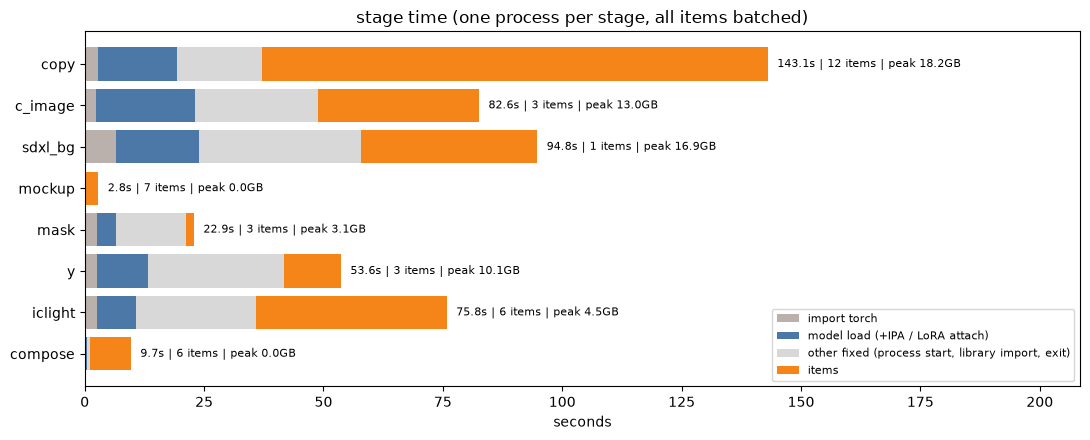

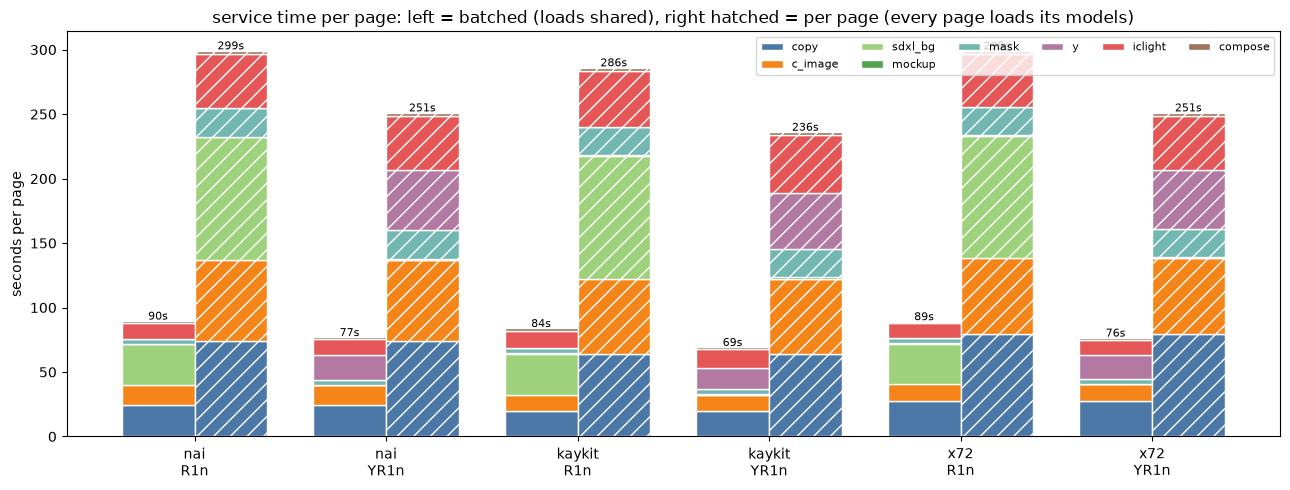

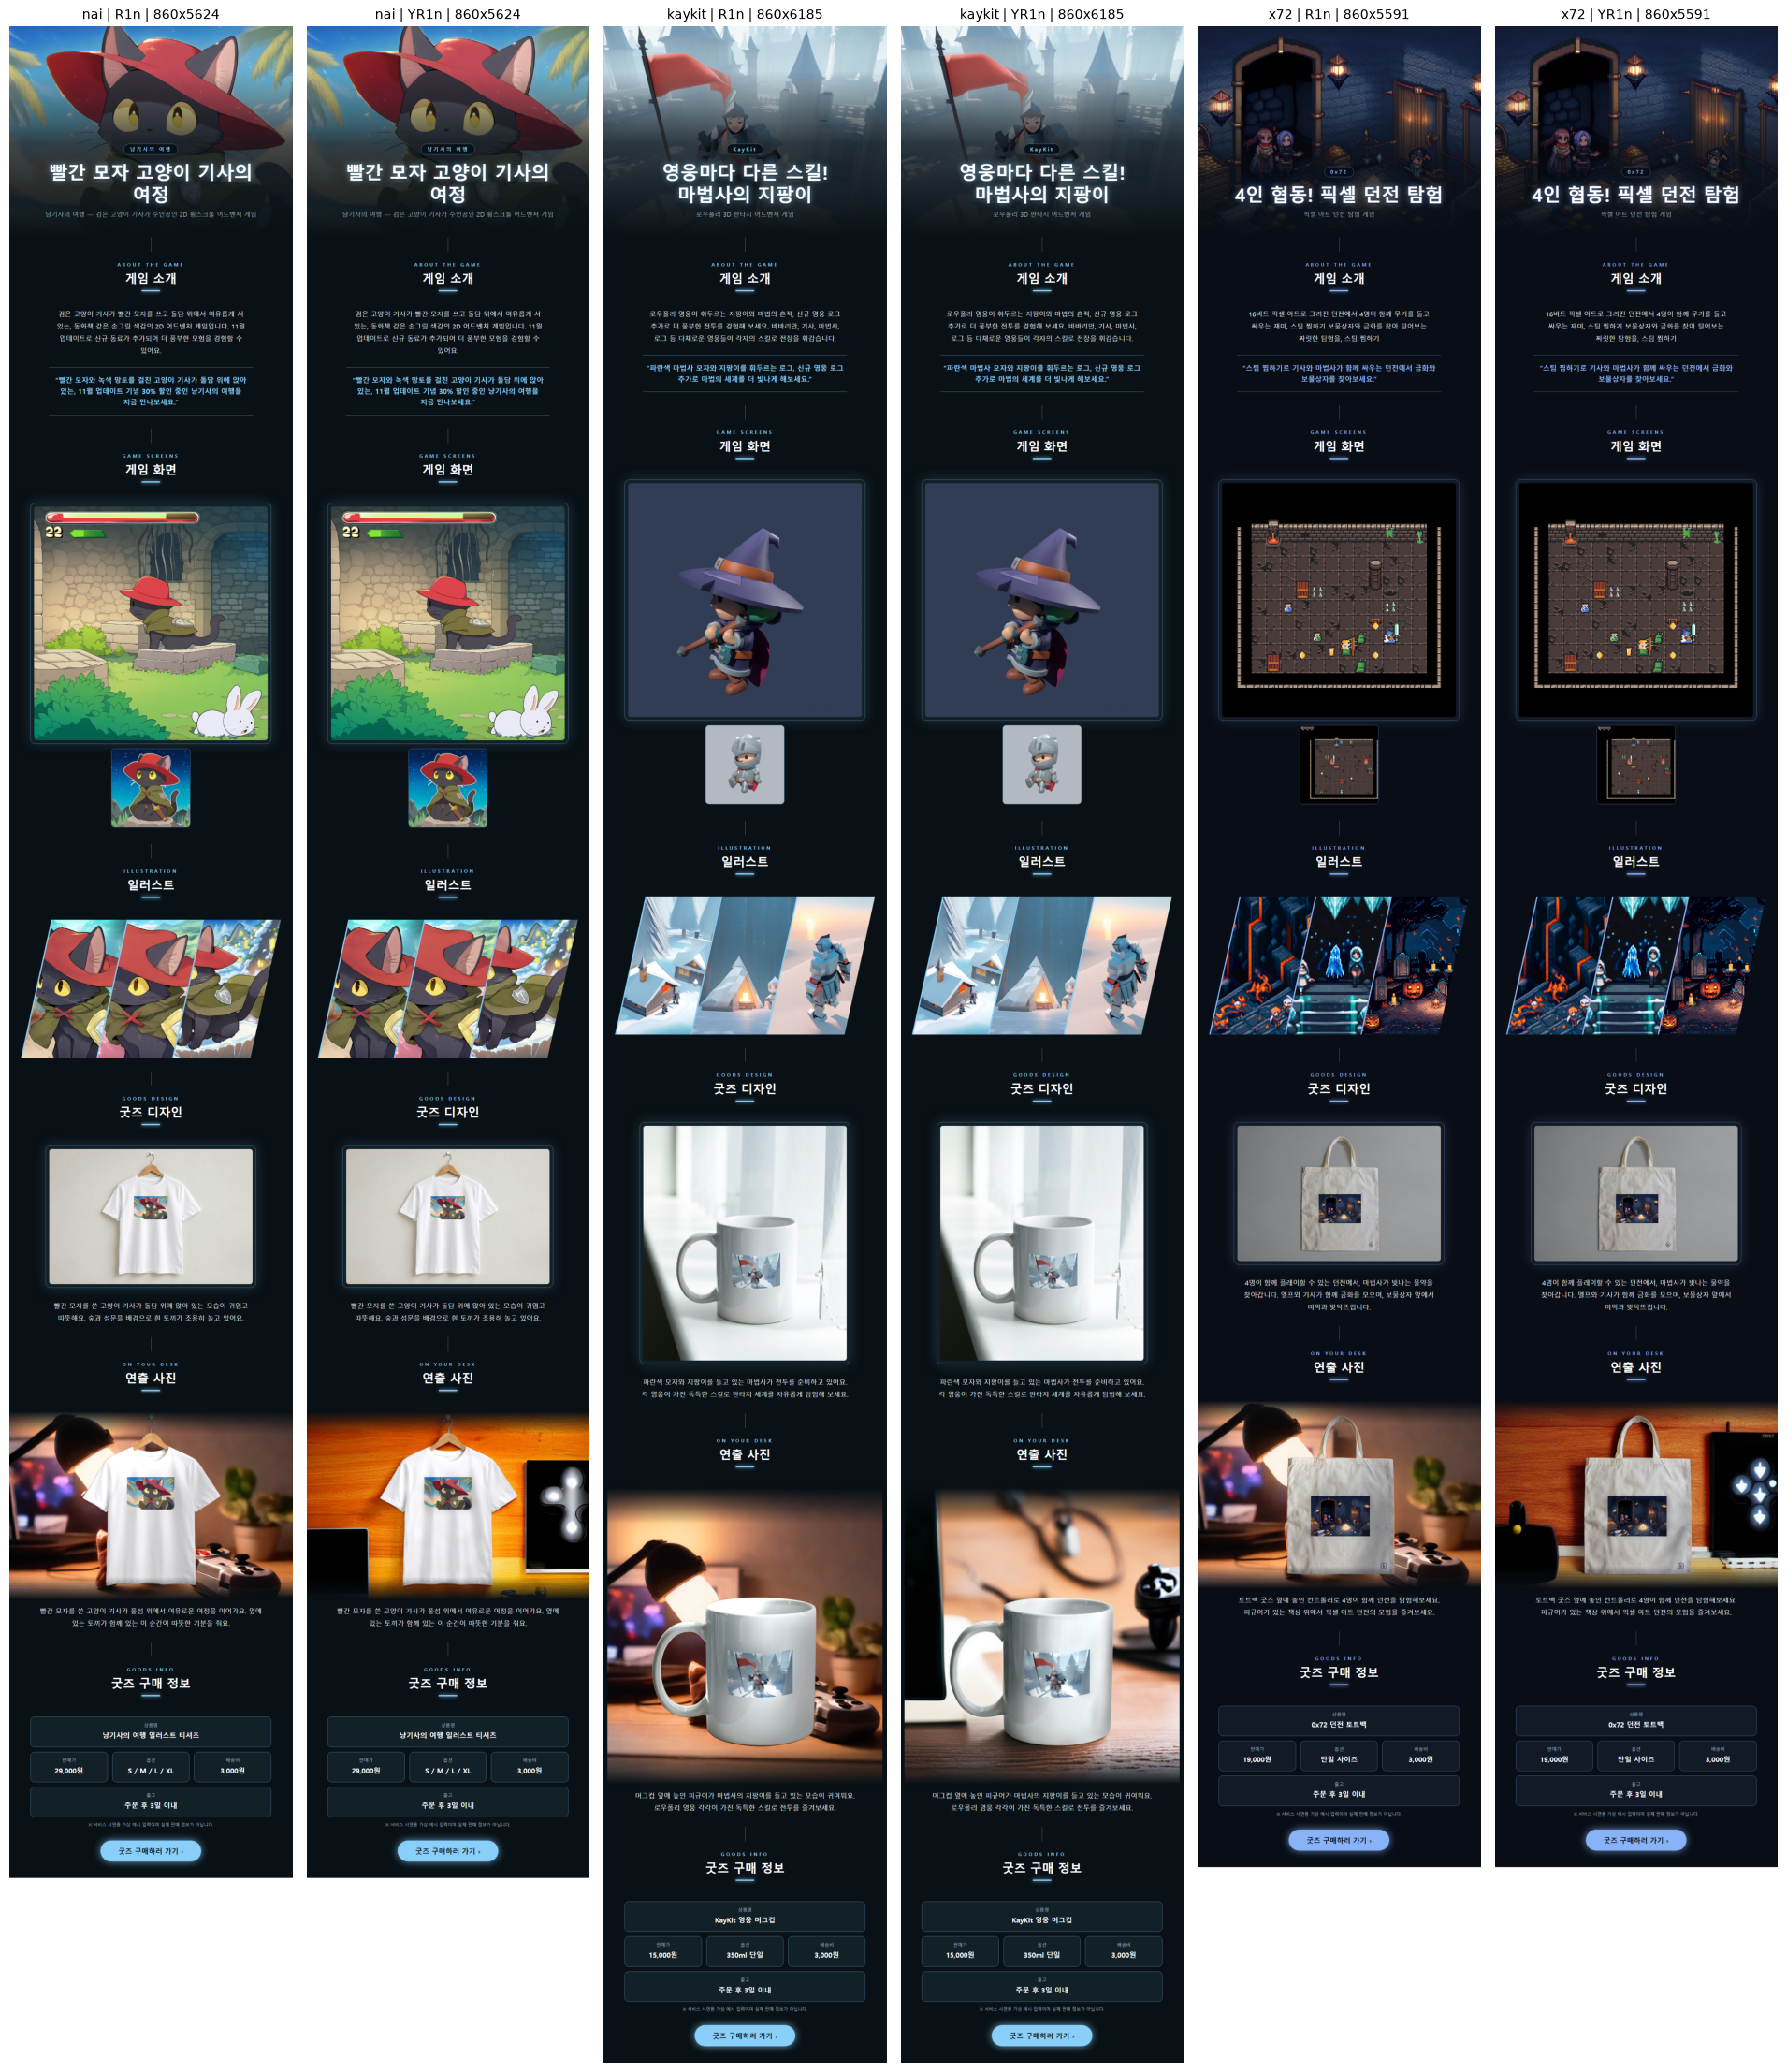

In [15]:
STAGE_COLOR = {'copy': '#4C78A8', 'c_image': '#F58518', 'sdxl_bg': '#9ED17B', 'mockup': '#54A24B', 'mask': '#72B7B2', 'y': '#B279A2', 'iclight': '#E45756', 'compose': '#9D755D'}
fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(latest))
imp = latest.import_sec.fillna(0)
load = latest.load_sec.fillna(0) + latest.extra_load_sec.fillna(0)
other = (latest.fixed_sec - imp - load).clip(lower=0)
left = np.zeros(len(latest))
for vals, lab, col in [(imp, 'import torch', '#BAB0AC'), (load, 'model load (+IPA / LoRA attach)', '#4C78A8'),
                       (other, 'other fixed (process start, library import, exit)', '#D8D8D8'), (latest.items_sec, 'items', '#F58518')]:
    ax.barh(y, vals, left=left, color=col, label=lab)
    left += vals.values
for i, s in enumerate(latest.index):
    ax.text(left[i] + 2, i, f"{latest.wall_sec[s]:.1f}s | {int(latest.n_ok[s])} items | peak {latest.peak_vram_gb[s]:.1f}GB", va='center',
            fontsize=8)
ax.set_yticks(y, latest.index)
ax.invert_yaxis()
ax.set_xlabel('seconds')
ax.set_xlim(0, left.max() * 1.45 + 1)
ax.set_title('stage time (one process per stage, all items batched)')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(OUT_DIR / 'dp_stage_times.png', dpi=90)
plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(svc))
for k, (mode, lab) in enumerate([('batched', 'batched'), ('per_page', 'per page (load every model)')]):
    bottom = np.zeros(len(svc))
    for s in STAGES:
        v = svc[f'{mode}_{s}'].values
        ax.bar(x + (k - 0.5) * 0.38, v, 0.38, bottom=bottom, color=STAGE_COLOR[s], edgecolor='white', hatch='' if k == 0 else '//',
               label=s if k == 0 else None)
        bottom += v
    for i, t in enumerate(bottom):
        ax.text(x[i] + (k - 0.5) * 0.38, t + 1, f'{t:.0f}s', ha='center', fontsize=8)
ax.set_xticks(x, [p.replace('__', '\n') for p in svc.page])
ax.set_ylabel('seconds per page')
ax.set_title('service time per page: left = batched (loads shared), right hatched = per page (every page loads its models)')
ax.legend(fontsize=8, ncol=6)
plt.tight_layout()
plt.savefig(OUT_DIR / 'dp_service_time.png', dpi=90)
plt.show()

ok_pages = [(k, f) for k, f in P_FILE.items() if img_done(f)]
ims = [Image.open(OUT_DIR / f) for _, f in ok_pages]
H = max(im.height for im in ims)
fig, axes = plt.subplots(1, len(ims), figsize=(3.2 * len(ims), 3.2 * H / PAGE_W), squeeze=False)
for ax, ((g, d), _), im in zip(axes[0], ok_pages, ims):
    canvas = Image.new('RGB', (PAGE_W, H), (255, 255, 255))
    canvas.paste(im, (0, 0))
    ax.imshow(canvas)
    ax.set_title(f'{g} | {d} | {im.width}x{im.height}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT_DIR / 'dp_pages_grid.png', dpi=60)
plt.show()